### Indentification of potential linkage pains

*Hitchhikers*: a synonymous SNV cooccuring with a non-synonymous SNV
*Cooccurrence*: a pair of two SNVs of the same mutation type cooccuring

Cooccurence here is identified by high correlation between the frequency trajectories and significance compared to random permutations of one of the frequency trajectory in the pair

## 0. General

In [1]:
import os, pandas as pd, numpy as np, scipy as sp, random
from Bio import SeqIO
import networkx as nx

In [2]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import matplotlib.gridspec as gridspec

import seaborn as sns

sns.set_theme(style="white", font="Arial")
sns.set_context({'font.size': 10.0, 'axes.labelsize': 12, 'axes.titlesize': 14,
                 'xtick.labelsize': 10, 'ytick.labelsize': 10, 'legend.fontsize': 10,
                 'legend.title_fontsize': None, 'axes.linewidth': 0.8, 'grid.linewidth': 0.8,
                 'lines.linewidth': 1.5, 'lines.markersize': 6.0, 'patch.linewidth': 1.0,
                 'xtick.major.width': 0.5, 'ytick.major.width': 0.5, 'xtick.minor.width': 0.3,
                 'ytick.minor.width': 0.3, 'xtick.major.size': 3.5, 'ytick.major.size': 3.5,
                 'xtick.minor.size': 2.0, 'ytick.minor.size': 2.0,})

plt.rcParams['xtick.bottom'] = True
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial']
plt.rcParams['font.size'] = 12
plt.rcParams['xtick.bottom'] = True
plt.rcParams['ytick.left'] = True


### 0.1. Load libraries

### 0.2. General variables

In [3]:
r_cutoff = 0.9 #cutoff used to identify potential pairs
detection_limit= 0.01

In [4]:
donors = [1,2,3,4]
replicates = ["A", "B", "C"]
passages = list(range(0, 110, 10))
tech_reps = [1,2 ]
populations = ["1A", "1B", "1C", "2A", "2B", "2C", "3A", "3B", "3C", "4A", "4B", "4C"]
segments = ["1-PB2", "2-PB1", "3-PA", "4-HA", "5-NP", "6-NA", "7-M", "8-NS"]

hours_per_passage = 72 #hours
generation_time = 6 #hours > assumption based on Baccam, et al. 2006

In [5]:
#color palette 
segment_cpal = ["#ea5545","#f46a9b", "#ef9b20", "#ede15b", "#87bc45", "#27aeef", "#776efa", "#b33dc6"]
population_cpal = [ "#005fb9", "#58b4e2", "#8ee6ff", "#860041", "#ca0090", "#ff53c0", "#006e00", "#77a908", "#bbe837", "#0000ba", "#5f38ed", "#d49eff" ]
driver_col, passenger_col, haplotype_col, wt_color=  "#d90368",  "#fb8b24", "#820263", "#EEEEEE"
snv1_col,snv2_col, haplotype_cooc_col = "#bce784","#5dd39e","#348aa7"

In [6]:
segment_nuc_cds = {r.id:r.seq for r in SeqIO.parse('../data/references/stock_consensus_cds.fasta', 'fasta')}


### 0.3. Functions

In [7]:
def null_model_trajectory_correlation(driver_freqs, passenger_freqs, bootstraps=10000):
    #might need to adapt this using depth and allele count in similar fashion to the error model...
    
    driver_delta = np.diff(driver_freqs)
    passenger_delta = np.diff(passenger_freqs)
    observed_r, observed_p = sp.stats.pearsonr(driver_delta, passenger_delta)
    
    null_dist = []
    
    for draw in range(bootstraps):
        #shuffle driver freqs
        driver_freqs_hat = np.random.permutation(driver_freqs)
        
        
        #change overtime 
        driver_delta_hat = np.diff(driver_freqs_hat)
        passenger_delta = np.diff(passenger_freqs)
        
        r, p = sp.stats.pearsonr(driver_delta_hat, passenger_delta)
        
        
        null_dist.append(r)
        
    null_dist = np.array(null_dist)
   
    return np.mean(null_dist >= observed_r) 

In [8]:
def get_hitchhiker_haplotypes(refname, snv_file, haplotype_dir, sample, technical_rep, refseq, freq_cutoff=None,):
    
    #get snv file used for haplotype 
    snv_df = pd.read_csv(snv_file)
    #ensure poistions are sorted
    snv_df = snv_df[snv_df["refname"]==refname].drop_duplicates().set_index(['nucpos', 'read_base']).sort_index() 
    #if freq cutoff is specified remove SNVs below frequency cutoff 
    if freq_cutoff is not None:
        snv_df = snv_df[snv_df["nuc_freq"]>=freq_cutoff]

    #get reconstruct state file 
    all_states  = pd.read_csv(os.path.join(haplotype_dir, "reconstruction", "-".join(sample.split("_")[0:2]), f"reconstructed_states_{sample}_{technical_rep}_{refname}.csv"))

    #get best haplotype results
    best_BIC = min(all_states['best BIC'])
    best_all_states_df = all_states[all_states['best BIC']==best_BIC]
    best_state = best_all_states_df.loc[best_all_states_df['LL'].idxmax()]
    best_freq = [float(v) for v in best_state["freq"].lstrip("[").rstrip("]").split(" ") if v != ""]
    best_haploset = eval(best_state['haplo set'])
    best_X_haplotype = best_state['X']
    best_LL = best_state['LL']

    # #safety check
    # if len(best_haploset[0]) !=  len(snv_df.index.get_level_values(0).unique()):

    #     print (f"haplotype length does not match the number of snvs for {sample} {technical_rep} {refname}")
    #     return [], []
    
    # #another safety check 
    # for nucpos in snv_df.index.get_level_values(0).unique():
    #     if len(snv_df.loc[[nucpos], :]) > 1:
    #         #print (f"more than one snv found at nucpos {nucpos} for {sample} {technical_rep} {refname}" )
    #         return [], []
        
    #get haplotype frequency from freq dist file
    freq_dist = pd.read_csv(os.path.join(haplotype_dir, "reconstruction", "-".join(sample.split("_")[0:2]), f"freq_dist_{sample}_{technical_rep}_{refname}.csv"), header=None)
    #taking mean haplotyp frequencies
    mean_freqs = [np.mean(freq_dist[c]) for c in freq_dist.columns]
        
    observed_haplotypes, observed_haplotype_frequencies = [], []
    for j, haploset in enumerate(best_haploset):
        snvs_in_haploset = []
        for i, base in enumerate(haploset):
            nucpos = snv_df.index.get_level_values(0).to_list()[i]
            if (nucpos, base) in snv_df.index.tolist():
                snvs_in_haploset.append(f"{refseq[nucpos-1]}{nucpos}{base}")
        observed_haplotypes.append(tuple(snvs_in_haploset))
        observed_haplotype_frequencies.append(mean_freqs[j])
    
    return observed_haplotypes, observed_haplotype_frequencies  

def get_cooccur_haplotypes(refname, snv_file, haplotype_dir, sample, technical_rep, refseq, freq_cutoff=None):
    
    #get snv file used for haplotype 
    snv_df = pd.read_csv(snv_file).drop_duplicates()
    #ensure poistions are sorted
    snv_df = snv_df[snv_df["refname"]==refname].set_index(['nucpos', 'read_base']).sort_index() 
    #if freq cutoff is specified remove SNVs below frequency cutoff 
    if freq_cutoff is not None:
        snv_df = snv_df[snv_df["nuc_freq"]>=freq_cutoff]
    
    
    #get reconstruct state file 
    all_states  = pd.read_csv(os.path.join(haplotype_dir, "reconstruction","-".join(sample.split("_")[0:2]), f"reconstructed_states_{sample}_{technical_rep}_{refname}.csv"))
    
    #get best haplotype results
    best_BIC = min(all_states['best BIC'])
    best_all_states_df = all_states[all_states['best BIC']==best_BIC]
    best_state = best_all_states_df.loc[best_all_states_df['LL'].idxmax()]
    best_freq = [float(v) for v in best_state["freq"].lstrip("[").rstrip("]").split(" ") if v != ""]
    best_haploset = eval(best_state['haplo set'])
    best_X_haplotype = best_state['X']
    best_LL = best_state['LL']

    #safety check
    if len(best_haploset[0]) !=  len(snv_df.index.get_level_values(0).unique()):
        print (f"haplotype length does not match the number of snvs for {sample} {technical_rep} {refname}")
        return [], []
    
    # #another safety check 
    # for nucpos in snv_df.index.get_level_values(0).unique():
    #     if len(snv_df.loc[[nucpos], :]) > 1:
    #         print (f"more than one snv found at nucpos {nucpos} for {sample} {technical_rep} {refname}" )
    #         return [], []
        
    #get haplotype frequency from freq dist file
    freq_dist = pd.read_csv(os.path.join(haplotype_dir, "reconstruction", "-".join(sample.split("_")[0:2]), f"freq_dist_{sample}_{technical_rep}_{refname}.csv"), header=None)
    #taking mean haplotyp frequencies
    mean_freqs = [np.mean(freq_dist[c]) for c in freq_dist.columns]
        
    observed_haplotypes, observed_haplotype_frequencies = [], []
    for j, haploset in enumerate(best_haploset):
        snvs_in_haploset = []
        for i, base in enumerate(haploset):
            nucpos = snv_df.index.get_level_values(0).to_list()[i]
            if (nucpos, base) in snv_df.index.tolist():
                snvs_in_haploset.append(f"{refseq[nucpos-1]}{nucpos}{base}")
        observed_haplotypes.append(tuple(snvs_in_haploset))
        observed_haplotype_frequencies.append(mean_freqs[j])

    return observed_haplotypes, observed_haplotype_frequencies  

def generate_haplotype_df(population, refname, raw_haplotypes, detection_limit=None):
    haplotype_df = raw_haplotypes[(raw_haplotypes["population"]==population)&(raw_haplotypes["refname"]==refname)]
    haplotype_df = haplotype_df.pivot(columns="passage", index="haplotype", values="frequency")
    if detection_limit is not None:
        #removing haplotypes that never exceed the detection limit
        keep = [hid for hid, row in haplotype_df.iterrows() if len([v for v in row.values if v >= detection_limit])>0]
        haplotype_df = haplotype_df[haplotype_df.index.isin(keep)]
    return haplotype_df


def get_haplotype_order(haplotype_df, timepoints):
    haplotype_order = [tuple()]
    previous_haplotypes = [tuple()] 
    ancestry_tracker = {}
    for pi, passage in enumerate(timepoints[1:], start=1):
        previous_passage = timepoints[pi-1]
        if passage not in haplotype_df.columns:
            previous_haplotypes = [tuple()]
            continue
            
        #find all current haplotypes 
        current_haplotypes = haplotype_df[haplotype_df[passage]>0].index.tolist()
        #seperate haplotype already in haplotype df from those first observed this time 
        seen_haplotypes = [haplotype for haplotype in current_haplotypes if haplotype in previous_haplotypes or haplotype==tuple()]
        seen_haplotypes.sort(key=lambda s: len(s))
        new_haplotypes =[haplotype for haplotype in current_haplotypes if haplotype not in previous_haplotypes and haplotype!=tuple()]
        new_haplotypes.sort(key=lambda s: len(s))
    
        #start with new haplotyes
        for hi, haplotype in enumerate(new_haplotypes):
            loss = False
            ancestral_haplotypes = [haplotype] #haplotype ancestry from haplotype back to wt
            if haplotype in haplotype_order:
                continue
            
            #determine potential parent haplos
            potential_parent_haplotypes = [ph for ph in previous_haplotypes if \
            set(haplotype).issubset(ph) or set(ph).issubset(haplotype) and len(ph)>0 and ph!=haplotype]
            #current haplotype gained and snv relative to potential parents
            gain_parents = [ph for ph in potential_parent_haplotypes if set(ph).issubset(haplotype) ]
            #current haplotype lost an snv relative to potential parents
            loss_parents = [ph for ph in potential_parent_haplotypes if set(haplotype).issubset(ph)]
            
            #find parent 
            if len(potential_parent_haplotypes) == 0:
                #only possible parent is wild_type
                parent = tuple()
                ancestral_haplotypes.append(parent)
            elif len(potential_parent_haplotypes) ==1:
                if len(gain_parents) == 1: #haplotype has gained an SNV
                    parent = gain_parents[0]
                    ancestral_haplotypes.append(parent)

                else:#haplotype has lost on SNV
                    parent = loss_parents[0]
                    ancestral_haplotypes.append(parent)
                    
            else:
                if len(gain_parents) > 0 and len(loss_parents) > 0:
                    #here i'm simply going to go with the ancestor with the highest previous frequency
                    parent = haplotype_df[haplotype_df.index.isin(potential_parent_haplotypes)]
                    parent = parent[parent[previous_passage]==max(parent[previous_passage].tolist())].index.values[0]
                    ancestral_haplotypes.append(parent)
                    
                elif len(gain_parents) > 0:#haplotype results from an SNV gain
                    #see the longest possible parent 
                    #assuming that the longer (the more matching snvs) the parent the more probable is in ancestral to the haplotype 
                    for l in reversed(range(len(haplotype))):
                        possible_parents = [ph for ph in gain_parents if len(ph)==l]
                        if len(possible_parents) == 0: 
                            continue
                        
                        #only one possible parent
                        if len(possible_parents) == 1:
                            parent = possible_parents[0]
                            ancestral_haplotypes.append(parent)
                            
                            break
                        else: #else multiple parents 
                            #assuming haplotype is descendant from parent with the highest haplotype freq
                            parent = haplotype_df.loc[possible_parents]
                            parent = parent[parent[previous_passage]==parent[previous_passage].max()].index.tolist()[0]
                            ancestral_haplotypes.append(parent)
                            break
                
                else: #haplotype results from a loss in snv 
                    #see the shortest possible parent 
                    #assuming that the longer (the more matching snvs) the parent the more probable is in ancestral to the haplotype 
                    for l in  range(len(haplotype)+1):
                        possible_parents = [ph for ph in potential_parent_haplotypes if len(ph)==l]
                        if len(possible_parents) == 0: 
                            continue
                    
                        #only one possible parent
                        if len(possible_parents) == 1:
                            parent = possible_parents[0]
                            ancestral_haplotypes.append(parent)
                            break

                        else:
                            #assuming haplotype is descendant from parent with the highest haplotype freq
                            parent = haplotype_df.loc[possible_parents]
                            parent = parent[parent[previous_passage]==parent[previous_passage].max()].index.tolist()[0]
                            ancestral_haplotypes.append(parent)
                            break

            #find ancestry  
            if parent in ancestry_tracker.keys():
                ancestral_haplotypes.extend(ancestry_tracker[parent])
            #see if ancestral line goes back to wild type 
            while ancestral_haplotypes[-1] != tuple():
                latest_ancestor = ancestral_haplotypes[-1]
                ancestral_haplotypes.extend(ancestry_tracker[latest_ancestor])
            ancestry_tracker[haplotype] = ancestral_haplotypes[1:]
            
            #insert haplotype correctly in haplotype order
            #need to insert haplotype after latest parent observation 
            parent_idx = [i for i, h in enumerate(haplotype_order) if h == parent][-1]

            
            if len (haplotype_order[parent_idx+1:]) >0:
                to_extend = []
                for h in ancestral_haplotypes:
                    if h == haplotype_order[parent_idx+1:][0]:
                        break
                    to_extend.append(h)
                
            else:
                to_extend = ancestral_haplotypes
                
            
            haplotype_order = haplotype_order[:parent_idx+1] + to_extend + haplotype_order[parent_idx+1:]
            
            

        previous_haplotypes = current_haplotypes


  
    return haplotype_order

def generate_haplotype_plotting_df(haplotype_df, timepoints, haplotype_order, detection_limit=None):
    haplotype_plotdf = []
    for pi, passage in enumerate(timepoints, start=1):
        passage_row = [0.] * len(haplotype_order)
        if passage not in haplotype_df.columns:
            #get number of wt columns
            haplotype = tuple()
            haplotype_idx =[i for i, h in enumerate(haplotype_order) if h == haplotype]
            freq = 1.
            for i in haplotype_idx:
                passage_row[i] = freq/len(haplotype_idx)
                
        else:
            nonzero_haplotypes = haplotype_df[haplotype_df[passage]>0].index.tolist()
            for haplotype in nonzero_haplotypes:
                haplotype_idx =[i for i, h in enumerate(haplotype_order) if h == haplotype]
                freq = haplotype_df.loc[[haplotype], passage].values[0]
                for i in haplotype_idx:
                    passage_row[i] = freq/len(haplotype_idx)
        
        haplotype_plotdf.append([passage]+ passage_row)
    #initialize df
    haplotype_plotdf = pd.DataFrame.from_records(haplotype_plotdf, columns=["passage"]+haplotype_order).set_index("passage")
    haplotype_plotdf.columns.name = "haplotype"
    haplotype_plotdf 
    
    if detection_limit is None:
        return haplotype_plotdf
    
    else:
        #iterate over observation below detection limit 
        for haplotype, row in haplotype_df.iterrows():
            if haplotype == tuple():
                continue
            for passage in haplotype_df.columns:
                if row[passage] < detection_limit:
                    #add frequency to parent
                    parent_idx = [i-1 for i, h in enumerate(haplotype_order) if h == haplotype]
                    for pi in parent_idx:
                        if haplotype_plotdf.iloc[timepoints.index(passage), pi] >0:
                            haplotype_plotdf.iloc[timepoints.index(passage), pi] += row[passage]/len(parent_idx)
                    
                    haplo_idx = [i for i, h in enumerate(haplotype_order) if h == haplotype]
                    for hi in haplo_idx:
                        haplotype_plotdf.iloc[timepoints.index(passage), hi] =0.
        
        #for cleaness of figure check > if total frequency sum to 1 
        #if not add remaining frequency according to proportion
        for i, passage in enumerate(timepoints):
            freq_sum = round(haplotype_plotdf.loc[passage].sum(),5)
            if freq_sum <1:
                remaining_freq = 1 - freq_sum
                for j, freq in enumerate(haplotype_plotdf.loc[passage].values):
                    if freq > 0:
                        new_freq = freq + ((freq/freq_sum)*remaining_freq)
                        haplotype_plotdf.iloc[i,j] = new_freq
           
    return haplotype_plotdf

def generate_color_per_haplotype(haplotype_order, haplotype_appearance=None, seed=None, non_synonymous_dict=None): 
    
    #coloring random
    if non_synonymous_dict is None:
        color_list = ['#A3CCC9','#02ABBD','#4A7FA0','#524FA1','#3132B7','#0978DC','#18825F','#489E10','#BBC735','#DDB40C','#F76C20',
                    '#ED4626','#DB2719','#B30219','#D0339C','#C42BD5','#912DD2',]

        # cmap = plt.colormaps['plasma']
        # color_list = [mpl.colors.to_hex(c) for c in cmap(np.linspace(0, 1, len(haplotype_appearance)))]
        if seed is not None:
            random.seed(seed)
            random.shuffle(color_list) 
    #coloring random but indicating last gain i.e. synonymous non synonymous
    else:
        color_list_nonsyn = [ "#693668", "#bd2d87", "#c52184", "#a30015", "#a74482", "#d664be", "#e574bc", "#f9b4ed", "#df99f0", "#f84aa7", "#ff3562", "#ff33cc" ]
        color_list_nonsyn = [ "#fa9fb5", "#f768a1", "#dd3497", "#ae017e", "#7a0177" ]
        color_list_syn = [ "#31572c", "#216869", "#235726", "#4f772d", "#53a548", "#4ccc55", "#00a66c", "#91cb3e", "#9cc5a1", "#90a955", "#abc72e"]
        color_list_syn = [ "#137547", "#2d6a4f", "#718355", "#007f5f", "#3fa34d", "#55a630", "#80b918", "#5bba6f", "#aacc00", "#bfd200", "#97a97c", "#b5c99a" ]
        if seed is not None:
            random.seed(seed)
            random.shuffle(color_list_nonsyn)
            random.shuffle(color_list_syn) 
            
    #if haplotype appearance is not specified infering from haplotype order
    if haplotype_appearance is None:
        haplotype_appearance = []
        for haplo in haplotype_order:
            if haplo!=tuple() and haplo not in haplotype_appearance:
                haplotype_appearance.append(haplo)
       
    if non_synonymous_dict is None:
        col_order = []
        for haplo in haplotype_order:
            if haplo == tuple():
                #col_order.append("#FFFFFF")
                col_order.append("#DDDDDD")
                
            else:
                i = haplotype_appearance.index(haplo)
                while i >= len(color_list):
                    i = i - len(color_list)
                
                col_order.append(color_list[i])
                
    else:
        col_order = []
        syn_c, ns_c = -1, -1
        for i, haplo in enumerate(haplotype_order):
            
            if haplo == tuple():
                #col_order.append("#FFFFFF")
                col_order.append("#DDDDDD")
                
            elif len(haplo) == 1:
                #if seen before
                if haplo in haplotype_order[:i-1]:
                    col_order.append(col_order[haplotype_order[:i-1].index(haplo)])
                
                elif haplo[0] in non_synonymous_dict:
                    ns_c += 1
                    if ns_c == len(color_list_nonsyn):
                        ns_c = 0
                    col_order.append(color_list_nonsyn[ns_c])
                else:
                    syn_c+= 1
                    if syn_c == len(color_list_syn):
                        syn_c = 0
                    col_order.append(color_list_syn[syn_c])
            else:
                if haplo in haplotype_order[:i-1]:
                    col_order.append(col_order[haplotype_order[:i-1].index(haplo)])
                else:
                    prev_haplo = haplotype_order[i-1]
                    
                    if len(prev_haplo) < len(haplo):
                        new_snv = tuple(set(haplo) - set(prev_haplo))[0]
                        if new_snv in non_synonymous_dict:
                            ns_c+=1 
                            if ns_c == len(color_list_nonsyn):
                                ns_c = 0
                            col_order.append(color_list_nonsyn[ns_c])
                        else:
                            syn_c += 1
                            if syn_c == len(color_list_syn):
                                syn_c = 0
                            col_order.append(color_list_syn[syn_c])
                    else:
                        
                        print ("loss I have not encountered this yet and need to write code for it ")

    return col_order  

def get_haplotype_appearance(haplotype_df):
    appearance_order = []
    for c in haplotype_df.columns:
        nonzero_haplotypes = [i for i, row in haplotype_df.sort_values(c, ascending=False).iterrows() if not pd.isna(row[c]) ]
        for haplotype in nonzero_haplotypes:
            if haplotype == tuple():
                continue
            if haplotype not in appearance_order:
                appearance_order.append(haplotype)
                
    return appearance_order

def draw_non_vertical_edges(collection, color='black', linewidth=1):
    
    ax = collection.axes #get ax from collection
    for path in collection.get_paths(): #go every polygon in the stackplot
        vertices = path.vertices
    
        if vertices.shape[0] < 2:
            continue
            
        num_sides = len(vertices) #get sides
        
        for i in range(num_sides):
            x1, y1 = vertices[i]
            
            
            if i < num_sides - 1: #skipping last 
                x2, y2 = vertices[i+1]
            else:
                continue 
            
            #find non-vertical edges
            if x1 != x2:
                line = Line2D([x1, x2], [y1, y2], color=color, linewidth=linewidth, linestyle='-',zorder=collection.get_zorder() + 1)
                ax.add_line(line)

def muller_plot(ax, timepoints, haplotype_plotdf, haplotype_order, haplotype_appearance=None, alpha=0.4, edgecolor="white", custom_color_list=None, color_seed=None, non_synonymous_dict=None):
    
    if custom_color_list is None:
        colors_plot = generate_color_per_haplotype(haplotype_order,haplotype_appearance, seed=color_seed, non_synonymous_dict=non_synonymous_dict)
    else:
        colors_plot =custom_color_list
    
    p = ax.stackplot(timepoints, haplotype_plotdf.values,edgecolors="none",
    linewidth=1, colors=colors_plot, alpha=alpha,)
    # #keep having weird horizonal lines no matter what i do, so creatively filling those up
    
    #spliting figure in passage chunks 
    for p, nextp in zip(timepoints[:-1], timepoints[1:]):
        df = haplotype_plotdf[[p, nextp]].reset_index()
        drop = [i for i, row in df.iterrows() if row[p]==0 and row[nextp]==0]
        df = df[~df.index.isin(drop)].set_index("haplotype")
        
        #see what haplotype Id levels can be merged
        ci = -1
        ndf = []
        for i, hid in enumerate(df.index):
            if i <= ci:
                continue
            li = i
            for j, nhid in enumerate(df.index[i+1:], start=i+1):
                if nhid != hid:
                    break
                else:
                    li = j
                    
            ndf.append([hid] + df.iloc[i:li+1, :].sum().values.tolist())
            ci= li
        ndf = pd.DataFrame.from_records(ndf, columns=["haplotype", p, nextp]).set_index("haplotype")
        
        #get colors for current level
        color_by_position = dict(zip(range(len(haplotype_order)), colors_plot))
        haplotype_to_indices = {}
        for idx, h in enumerate(haplotype_order):
            haplotype_to_indices.setdefault(h, []).append(idx)

        color_list = [color_by_position[haplotype_to_indices[hid][0]] for hid in ndf.index.tolist()]


        plot = ax.stackplot([p, nextp],ndf.values,edgecolors='none',
                        linewidth=1, colors=color_list, alpha=alpha, zorder=10)
    
        for collection in plot:
            draw_non_vertical_edges(collection, color=edgecolor, linewidth=0.5) 


    return p  

def muller_plot_cosmetics(ax, timepoints, ylabel=False, ylabelsize=8):
    ax.set_xlim(-0, timepoints[-1])
    ax.spines[['top','right']].set_visible(False)
    ax.set_ylim(0,1)
    ax.set_yticklabels([])
    ax.axvline(0, color="black", zorder=100, lw=0.5)
    if ylabel: 
        ax.set_ylabel("relativeabundance")

def annotate_muller_plot( ax,haplotype_df,haplotype_plotdf, non_synonymous_dict, color_dict, textsize=8):
    
    texts = []
    for haplotype, row in haplotype_df.iterrows():
        plotdf_idx = [i for i, c in enumerate(haplotype_plotdf.columns) if c == haplotype]
        
        if haplotype == tuple():

            continue  # skip wildtype

        tf = 0.1 if row.dropna().max() > 0.1 else 0.05 if row.dropna().max() > 0.05 else row.dropna().max()
        x = [p for p, f in row.dropna().items() if f >= tf][0]
        
        pi = haplotype_plotdf.index.tolist().index(x)

        y = sum(haplotype_plotdf.iloc[pi, :min(plotdf_idx)])
        y += sum(haplotype_plotdf.iloc[pi, plotdf_idx]) / 2.5

        parent_haplotype = haplotype_plotdf.columns[min(plotdf_idx) - 1]

        #haplotype has gained an SNV relative to its parent
        if len(parent_haplotype) < len(haplotype):
            acquired_snvs = sorted([snv for snv in haplotype if snv not in parent_haplotype], key=lambda s: int(s[1:-1]))

            t = ax.text(x - 2 if x == 100 else x, y, ",\n".join(acquired_snvs),
                        color="white", fontsize=textsize, fontweight="bold", ha="center" if x != 100 else "right",
                        zorder=20, bbox=dict(facecolor=color_dict[haplotype], alpha=0.5, pad=1, edgecolor="none"))
        
            texts.append(t)

        #haplotype has lost an SNV relative to its parent
        else:
            lost_snvs = sorted([snv for snv in parent_haplotype if snv not in haplotype], key=lambda s: int(s[1:-1]))

            t = ax.text(x - 2 if x == 100 else x, y, ",\n".join(lost_snvs), 
                        color="#FF33CC", fontsize=textsize, fontweight="bold",  ha="center" if x != 100 else "right", 
                        zorder=20, bbox=dict( facecolor=color_dict[haplotype], alpha=0.5, pad=1, edgecolor="none"))
            
            texts.append(t)
            
   
    return texts
 
def resolve_text_overlaps(ax, texts, padding=0.02, x_step=2, max_iter=200):
    fig = ax.figure
    renderer = fig.canvas.get_renderer()
    
    x_min, x_max = ax.get_xlim()
    y_min, y_max = ax.get_ylim() # y_min should be 0

    initial_x = {t: t.get_position()[0] for t in texts}
    initial_y = {t: t.get_position()[1] for t in texts} 
    
    for _ in range(max_iter):
        moved = False
        bboxes = [t.get_window_extent(renderer=renderer).transformed(ax.transData.inverted()) for t in texts]

        for i in range(len(texts)):
            for j in range(i + 1, len(texts)):
                bbox_i = bboxes[i]
                bbox_j = bboxes[j]
                text_j = texts[j]
                
                if bbox_i.overlaps(bbox_j):
                    x_j, y_j = text_j.get_position()
                    
                    # first testing y adjustment 
                    if x_j == initial_x[text_j]: #x positon has not been adjusted 
                        #first moving label down
                        new_y = y_j - padding
                        #calculating new position
                        temp_bbox_j = bbox_j.translated(0, new_y - y_j)
                        #see if new position is within the plotting area
                        if temp_bbox_j.y0 > y_min:
                            text_j.set_position((x_j, new_y))
                            moved = True
                            continue # skipping x adjustment and testing for upward not 
                        
                        #if downward move failed testing upward move 
                        new_y = y_j + padding
                        temp_bbox_j = bbox_j.translated(0, new_y - y_j)
                        
                        if temp_bbox_j.y1 < y_max:
                            text_j.set_position((x_j, new_y))
                            moved = True
                            continue ## skipping x adjustment
                       
                    #if y adjust was unsuccessfull 
                    best_x = None
                    best_distance = float('inf')
                    current_horizontal_overlap = max(0, min(bbox_i.x1, bbox_j.x1) - max(bbox_i.x0, bbox_j.x0))
                    
                    #testing shift to the right
                    x_right = x_j + x_step
                    if x_right + bbox_j.width/2 < x_max:
                        temp_bbox_j = bbox_j.translated(x_right - x_j, 0)
                        
                        new_horizontal_overlap = max(0, min(bbox_i.x1, temp_bbox_j.x1) - max(bbox_i.x0, temp_bbox_j.x0))
                        
                        if new_horizontal_overlap < current_horizontal_overlap:
                            distance = abs(x_right - initial_x[text_j])
                            if distance < best_distance:
                                best_x = x_right
                                best_distance = distance
                                
                    #testing shift to the left 
                    x_left = x_j - x_step
                    if x_left - bbox_j.width/2 > x_min:
                        temp_bbox_j = bbox_j.translated(x_left - x_j, 0)
                        
                        new_horizontal_overlap = max(0, min(bbox_i.x1, temp_bbox_j.x1) - max(bbox_i.x0, temp_bbox_j.x0))

                        if new_horizontal_overlap < current_horizontal_overlap:
                            distance = abs(x_left - initial_x[text_j])
                            if distance < best_distance:
                                best_x = x_left
                                best_distance = distance
                                
                    # apply best x shift 
                    if best_x is not None:
                        #if x position is change we force Y back to its original position
                        text_j.set_position((best_x, initial_y[text_j])) 
                
                        moved = True

        if not moved:
            break
        
def highlight_non_synonymous_snvs(ax, texts, non_synonymous_dict, underline_frac=0.08, lw=1):
    fig = ax.figure
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    for t in texts:
        snvs = t.get_text().split(",\n")

        if not snvs:
            continue

        # get text bbox in data coordinates
        bbox = t.get_window_extent(renderer=renderer)
        bbox_data = bbox.transformed(ax.transData.inverted())

        n_lines = len(snvs)
        line_height = bbox_data.height / n_lines

        for i, snv in enumerate(snvs):
            if snv not in non_synonymous_dict:
                continue

            # y-position of underline (matches old logic)
            y_line = (bbox_data.y1  - (i + 1) * line_height + line_height * underline_frac)

            ax.plot([bbox_data.x0, bbox_data.x1], [y_line, y_line], color=t.get_color(),
                    lw=lw, zorder=t.get_zorder() + 1, clip_on=True,)


## 1. load data and linkage disequilibrium prep

As infleunza's genome is segmented we can only do linkage disequilibrium (LD) for identified potential (we won't know for sure, as we didn't do long read sequencing) linked pairs located on the same segment. for LD with need to infer the frequency of the halpotype carrying both of the linked SNVs, which we do via haplotype reconstruction. If you which the regenerate the haplotype reconstruction in full change the run boolean to True 

In [9]:
#load data
#load snv summary 
snv_summary = pd.read_csv("../results/snv_summary_annotated.csv", keep_default_na=False, na_values=[""]).set_index(["population", "refname", "nucpos", "snv"]).sort_index()

#create overview of non-synonymous SNVs (for convienence)
non_synonymous_dict = {segment:[] for segment in segments}
for i in snv_summary[snv_summary["non_synonymous"]==True].index.droplevel(0):
    non_synonymous_dict[i[0]].append(i[-1])
    
snv_complete_overview = pd.read_csv("../results/snv_frequencies_complete.csv").set_index(["population", "refname", "nucpos", "read_base", "snv"]).sort_index()

#load trajectories 
trajectories = pd.read_csv("../results/snv_trajectories.csv").set_index(["population", "refname", "nucpos", "snv"]).sort_index()
trajectories = trajectories.rename(columns={c:int(c) for c in trajectories.columns})

#coverage dir should exist and contain all nucleotide coverage files
coverage_dir = "../results/nucleotide_coverage"

In [10]:
run = False #change to true if you want to run the haplotype reconstruction 
if run:
    align_dir = "../results/sorted_aligned_read_jsons"
    if not os.path.isdir(align_dir):
        print ("Warning sorted aligned read output from flu-tube.py is missing haplotype reconstruction can not be ran without this data")
    
    
    #hitchikers 
    haplotype_hitchhiker_dir = "../results/haplotype_reconstruction/hitchhikers"
    if not os.path.isdir(haplotype_hitchhiker_dir):
        os.makedirs(haplotype_hitchhiker_dir)
    haplotype_hitchhiker_input_dir = os.path.join(haplotype_hitchhiker_dir, "input")
    if not os.path.isdir(haplotype_hitchhiker_input_dir):
        os.makedirs(haplotype_hitchhiker_input_dir)
    haplotype_hitchhiker_results_dir = os.path.join(haplotype_hitchhiker_dir, "reconstruction")
    if not os.path.isdir(haplotype_hitchhiker_results_dir):
        os.makedirs(haplotype_hitchhiker_results_dir)
        
    haplotype_hitchhiker_bash_script = "../scripts/bash/hitchhiker_haplotype_reconstruction.sh"
    
    #co-occurrence
    haplotype_cooccurence_dir = "../results/haplotype_reconstruction/cooccurence"
    if not os.path.isdir(haplotype_cooccurence_dir):
        os.makedirs(haplotype_cooccurence_dir)
    haplotype_cooccurence_input_dir = os.path.join(haplotype_cooccurence_dir, "input")
    if not os.path.isdir(haplotype_cooccurence_input_dir):
        os.makedirs(haplotype_cooccurence_input_dir)
    haplotype_cooccurence_results_dir = os.path.join(haplotype_cooccurence_dir, "reconstruction")
    if not os.path.isdir(haplotype_cooccurence_results_dir):
        os.makedirs(haplotype_cooccurence_results_dir)
        
    haplotype_cooccurence_bash_script = "../scripts/bash/hitchhiker_cooccurence_reconstruction.sh"
        
hitchhiker_haplotype_file = "../results/hitchhiker_haplotype.csv"
cooccurence_haplotype_file = "../results/cooccurence_haplotype.csv"



## 2. Hitchhicker identification

### 2.1. identification of potential driver passenger pairs

**potential pairs**:   
synonymous SNV should arise in the background on the non-synonymous snvs. So based on this logic the frequency of the synymous SNV should be lower than the frequency of the non-synonymous SNV. frequency of the non-synymous SNVs should also be above a certain limit (e.g. 50%) because fixation of the synonymous SNV needs to be the result of the fixation of the non-synonymous SNVs. frequency cutoff for potential pairs should be before the "selective sweep" of the non-synonymous SNV

**Trajectory correlation**:  
if driver and passenger SNVS are true driver and passenger pairs the change if frequency of these SNVs over time should be heavily correlated
NOTE: something flawed if the driver emerges before the passenger the change in frequency might not be as correlated so going on this metric alone might not be the way to go

Also checking if this happens across segments > highly correlation trajectories. Cannot determine Linkage because of them occuring on different segments

In [11]:
driver_passenger_pairs = []
for population in populations:
    
    #get observed snvs for that population 
    df = snv_summary.loc[population]
    #removing drifters
    df = df[df["status"]!="drift"]

    #identify potential drivers and potential passengers
    driver_snvs = [idx for idx in df.index.unique() if True in df.loc[idx, ["non_synonymous"]].values]
    passenger_snvs = [idx for idx in df.index.unique() if True not in df.loc[idx, ["non_synonymous"]].values]

    for driver in driver_snvs:
        for passenger in passenger_snvs:
            driver_freqs = trajectories.loc[population].loc[driver].values
            passenger_freqs = trajectories.loc[population].loc[passenger].values
            
            # #difference in frequency at anypoint in time can not be greater than 0.25 SAFETY
            if any(abs(f-passenger_freqs[fi])>0.25 for fi, f in enumerate(driver_freqs)):
                continue
            # and max passenger frequence  can not be higher than max driver freqs
            if max(passenger_freqs) > max(driver_freqs) + 0.01: #0.01 to avoid small decimal difference
                continue
            
            
            #change over time
            driver_delta = np.diff(driver_freqs)
            passenger_delta = np.diff(passenger_freqs)
            
            r, p = sp.stats.pearsonr(driver_delta, passenger_delta)
            
            #if p <0.2 and r>r_cutoff: #only running null model if there is significant evidence 0.05 is too strict and r > 0.85
            if r>r_cutoff: #only running null model if there is significant evidence 0.05 is too strict and r > 0.85
                p_null_model = null_model_trajectory_correlation(driver_freqs, passenger_freqs, bootstraps=10000)
                if p_null_model <0.05:
                    
                    
                    try:
                        status_driver = df.loc[driver, "status"].values[0]
                    except:
                        status_driver = df.loc[driver, "status"]
                    try:
                        status_passenger = df.loc[passenger, "status"].values[0]
                    except:
                        status_passenger = df.loc[passenger, "status"]
                        
                    
                    driver_passenger_pairs.append([population, driver[0], driver[1], driver[2], status_driver, passenger[0], passenger[1], passenger[2], status_passenger,
                                            round(r, 4), round(p, 4), round(p_null_model, 4),  p<0.05, p_null_model<0.05])
        
driver_passenger_pairs = pd.DataFrame.from_records(driver_passenger_pairs, columns=["population", "driver refname", "driver nucpos", "driver snv", "driver status", "passenger refname", "passenger nucpos", "passenger snv", "passenger status",
                                                                "r", "p-value", "p-value null model", "significant", "significant null model"])        
      


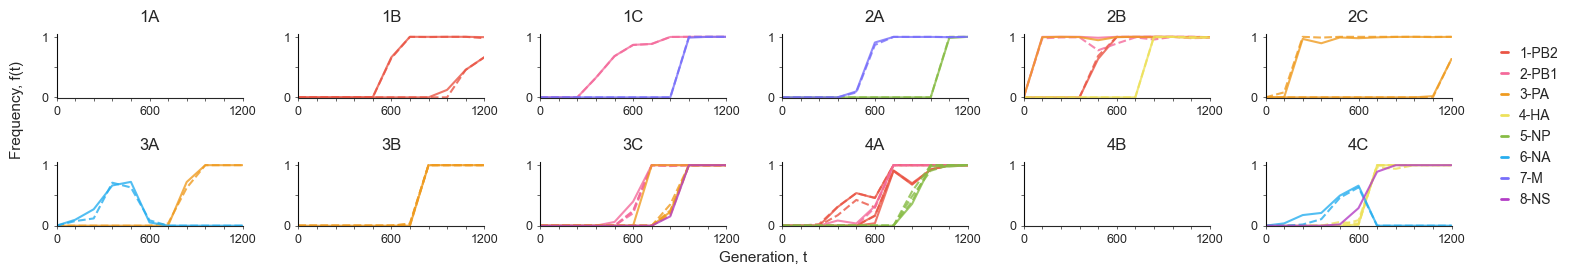

In [12]:
#visualize trajectoriies
fig = plt.figure(figsize=(18, 2.5))
max_panels = 12
gs = gridspec.GridSpec(2,6, wspace=0.3, hspace=1)

offset = 0

#prep legends
segment_legend_elements = []#
for i , s in enumerate(segments):
    segment_legend_elements.append(Line2D([0], [0], color=segment_cpal[i], label=s, linewidth=2,  ))
    

for i, population in enumerate(populations):
     
    df = driver_passenger_pairs[driver_passenger_pairs["population"]==population].set_index(["driver refname", "driver nucpos", "driver snv"])
    ax = fig.add_subplot(gs[i])
    
    plotted = []
    
    for j, (driver_refname, driver_nucpos, driver_snv) in enumerate(df.index.unique()):
        if (driver_refname, driver_nucpos, driver_snv) not in plotted:
            freqs = trajectories.loc[(population, driver_refname, driver_nucpos, driver_snv)].values.tolist()
            ax.plot([p-offset for p in passages], freqs, lw=1.5, alpha=0.8, color=segment_cpal[segments.index(driver_refname)])
            plotted.append((driver_refname, driver_nucpos, driver_snv))
        
        sdf = df.loc[[(driver_refname, driver_nucpos, driver_snv)]].reset_index().set_index(['passenger refname', 'passenger nucpos', 'passenger snv'])
        for k, (passenger_refname, passenger_nucpos, passenger_snv) in enumerate(sdf.index):
            if (passenger_refname, passenger_nucpos, passenger_snv) not in plotted:
                freqs = trajectories.loc[(population, passenger_refname, passenger_nucpos, passenger_snv)].values.tolist()
                ax.plot([p+(offset*k) for p in passages], freqs, lw=1.5, alpha=0.8, color=segment_cpal[segments.index(driver_refname)], ls="--")
                plotted.append((passenger_refname, passenger_nucpos, passenger_snv))
            
    
    ax.spines[['top','right']].set_visible(False)
    ax.set_xlim(-0, passages[-1])
    ax.axvline(0, color="black", zorder=100, lw=0.5)
    
    ax.set_ylim(-0.01,1.05)
    ax.set_yticks([0, 0.5, 1.0])
    ax.set_yticklabels(["0", "", "1"], size=9)

   
    ax.set_xticks(passages)
    ax.set_xticklabels([])
    ax.tick_params(axis='both', which='both', length=2)  
    ax.set_xticklabels([int((p*hours_per_passage)/generation_time) if p%50==0 else "" for p in passages], size=9)
        
    if i == 8:
        ax.text(120, -0.6, "Generation, t", size=11, ha="center")
    if i ==0:
        ax.text(-25, -0.2, "Frequency, f(t)", size=11, rotation=90, va="center")
        
    ax.text(50,1.2, population, ha="center", va="bottom", size=12)

    if i==5:
        ax.legend(handles=segment_legend_elements, loc='upper left', bbox_to_anchor=(1.2,1), ncols =1, fontsize=10, handlelength=0.5,
                                edgecolor=None, frameon=False, columnspacing=0.5)    


In [13]:
driver_passenger_pairs.to_csv("../results/identified_putative_hitchhikers.csv")

### 2.2.  Linkage disequillibrium for hitchhikers on the same segment

the **coefficient of linkage disequilibrium** is defined as: $ D = P_{AB} -P_{A}P_{B}$   
where $P_{AB}$ is the frequency of the haplotype carrying both alllele A and B, $P_{A}$ is the frequency of allele A, and $P_{B}$ is the frequency of allele B.

the range of possible values for D depend on the allele frequency, so to compare in the LD coefficent D over time we can **normalize D** via:  
$D' = \frac{D}{D_{max}}$  where  $D_{max}=\Big\{ \begin{aligned} & max\left\{-P_{A}P_{B},-(1-P_{A})(1-P_{B})\right\}  \\ & min\left\{P_{A}(1-P_{B}),P_{B}(1-P_{A})\right\}  \\ \end{aligned}$      $\begin{aligned} & when D < 0   \\ & when D > 0 \\ \end{aligned}$ 

the correlation coefficient can be calculated via: $r^{2} =\frac{D^{2}}{P_{A}(1-P_{A})P_{B}(1-P_{B})}$

In [14]:
#get hitchhikers on the same segment
same_segment_driver_passenger_pairs = driver_passenger_pairs[driver_passenger_pairs["driver refname"]==driver_passenger_pairs["passenger refname"]].reset_index(drop=True)


#### 2.2.1. Run haplotype reconstruction and get results

In [15]:
if run:
    n_threads = 1 #recommend keeping at one > each command is already segment specific 
    cmd_list = []

    prep_df = snv_complete_overview.copy().reset_index().set_index(["population", "passage", "refname"]).sort_index()

    for i, row in same_segment_driver_passenger_pairs.iterrows():
        population, refname = row[0:2]
        donor, replicate = population
        donor = int(donor)
        
        driver = tuple(row[2:4])
        passenger = tuple(row[6:8])

        #get trajectory of driver and passenger
        df = trajectories.loc[(population, refname)].loc[[driver, passenger]]

        #reconstruction haploptype for each passage in which at least one of the SNVs has a frequency 
        for passage in passages[1:]:
            sample = f"P{passage}-{population}"
            samp_dir =  os.path.join(haplotype_hitchhiker_results_dir, sample)
                
            if len(df[df[passage]>0])>0:
                
                nucpos_list = df[df[passage]>0].index.get_level_values(0).tolist()
                vdf = prep_df.loc[(population, passage, refname)].reset_index()
                vdf = vdf[vdf["nucpos"].isin(nucpos_list)]
                vdf["refname"] = refname
                
                for tr in tech_reps:
                    tdf = vdf[["refname", "nucpos", "snv", "read_base", f"coverage|tr{tr}", f"nuc_count|tr{tr}", f"nuc_freq|tr{tr}"]]
                    tdf = tdf.rename(columns={c:c.split("|")[0] for c in tdf.columns})
                    
                    fn = f"P{passage}_{population}_{refname}_{driver[-1]}_{passenger[-1]}_{tr}.csv"
                    fn = os.path.join(haplotype_hitchhiker_input_dir, fn)
                    
                    tdf.to_csv(fn, index=False)
                    
                    coverage_file = os.path.join(coverage_dir, f"nuc_coverge_P{passage}-{population}_{tr}.csv")
                    read_files = [os.path.join(align_dir,  f'{sample}_{tr}_reads.json.jz')]
                    
                    cmd = ['python', './scripts/haplotype_reconstruction.py', '-s', fn.replace("../", "./"), '-c', coverage_file.replace("../", "./"), '-r', " ".join([f.replace("../", "./") for f in read_files]), 
                '-o', samp_dir.replace("../", "./"), '-t', str(n_threads), '-sn', f"P{passage}_{population}_{refname}_{driver[-1]}_{passenger[-1]}_{tr}",]

                    cmd_list.append(" ".join(cmd))

    with open(haplotype_hitchhiker_bash_script, "w") as fw:
        fw.write("#!/bin/bash\n")
        fw.write('cd ~/LTEE-flu\n\n') #change to actual location of the repo
        for cmd in cmd_list:
            fw.write(f"{cmd}\n")
                        

In [16]:
def get_hitchhiker_haplotypes(refname, snv_file, haplotype_dir, sample, technical_rep, refseq, freq_cutoff=None,):
    
    #get snv file used for haplotype 
    snv_df = pd.read_csv(snv_file)
    # if len(snv_df) > 2:
    #     display(snv_df)
    #ensure poistions are sorted
    snv_df = snv_df[snv_df["refname"]==refname].drop_duplicates().set_index(['nucpos', 'read_base']).sort_index() 
    #if freq cutoff is specified remove SNVs below frequency cutoff 
    if freq_cutoff is not None:
        snv_df = snv_df[snv_df["nuc_freq"]>=freq_cutoff]

    #get reconstruct state file 
    all_states  = pd.read_csv(os.path.join(haplotype_dir, "reconstruction", "-".join(sample.split("_")[0:2]), f"reconstructed_states_{sample}_{technical_rep}_{refname}.csv"))

    #get best haplotype results
    best_BIC = min(all_states['best BIC'])
    best_all_states_df = all_states[all_states['best BIC']==best_BIC]
    best_state = best_all_states_df.loc[best_all_states_df['LL'].idxmax()]
    best_freq = [float(v) for v in best_state["freq"].lstrip("[").rstrip("]").split(" ") if v != ""]
    best_haploset = eval(best_state['haplo set'])
    best_X_haplotype = best_state['X']
    best_LL = best_state['LL']

    # #safety check
    # if len(best_haploset[0]) !=  len(snv_df.index.get_level_values(0).unique()):

    #     print (f"haplotype length does not match the number of snvs for {sample} {technical_rep} {refname}")
    #     return [], []
    
    # #another safety check 
    # for nucpos in snv_df.index.get_level_values(0).unique():
    #     if len(snv_df.loc[[nucpos], :]) > 1:
    #         #print (f"more than one snv found at nucpos {nucpos} for {sample} {technical_rep} {refname}" )
    #         return [], []
        
    #get haplotype frequency from freq dist file
    freq_dist = pd.read_csv(os.path.join(haplotype_dir, "reconstruction", "-".join(sample.split("_")[0:2]), f"freq_dist_{sample}_{technical_rep}_{refname}.csv"), header=None)
    #taking mean haplotyp frequencies
    mean_freqs = [np.mean(freq_dist[c]) for c in freq_dist.columns]
        
    observed_haplotypes, observed_haplotype_frequencies = [], []
    for j, haploset in enumerate(best_haploset):
        snvs_in_haploset = []
        for i, base in enumerate(haploset):
            nucpos = snv_df.index.get_level_values(0).to_list()[i]
            if (nucpos, base) in snv_df.index.tolist():
                snvs_in_haploset.append(f"{refseq[nucpos-1]}{nucpos}{base}")
        observed_haplotypes.append(tuple(snvs_in_haploset))
        observed_haplotype_frequencies.append(mean_freqs[j])
    
    return observed_haplotypes, observed_haplotype_frequencies



In [17]:
if run:
    hitchhiker_haplotypes = []
    prep_df = snv_complete_overview.copy().reset_index().set_index(["population", "passage", "refname"]).sort_index()

    for i, row in driver_passenger_pairs.iterrows():
        if row['driver refname'] != row['passenger refname']:
            continue
        
        population, refname = row[0:2]
        donor, replicate = population
        donor = int(donor)
        
        driver = tuple(row[2:4])
        passenger = tuple(row[6:8])
        
        #get trajectory of driver and passenger
        df = trajectories.loc[(population, refname)].loc[[driver, passenger]]
        
        haplotype_df = []
        for passage in passages[1:]:
            if len(df[df[passage]>0])>0:
                
                #vdf = variants.loc[(donor, replicate, passage, refname)].reset_index()
                vdf = prep_df.loc[(population, passage, refname)].reset_index()
                vdf = vdf[vdf["nucpos"].isin(nucpos_list)]
            
                fn = f"P{passage}_{population}_{refname}_{driver[-1]}_{passenger[-1]}_{tr}.csv"
                fn = os.path.join(haplotype_hitchhiker_input_dir, fn)
                sample = f"P{passage}_{population}_{refname}_{driver[-1]}_{passenger[-1]}"
                
                observed_haplotypes_1, observed_haplotype_frequencies_1 = get_hitchhiker_haplotypes (refname, fn, haplotype_hitchhiker_dir, f"{sample}", 1, segment_nuc_cds[refname])
                
                try:
                    observed_haplotypes_1, observed_haplotype_frequencies_1 = get_hitchhiker_haplotypes (refname, fn, haplotype_hitchhiker_dir, f"{sample}", 1, segment_nuc_cds[refname])
                except:
                    observed_haplotypes_1, observed_haplotype_frequencies_1 = [], []
                    
                #technical replicate 2
                try:
                    observed_haplotypes_2, observed_haplotype_frequencies_2 = get_hitchhiker_haplotypes (refname, fn, haplotype_hitchhiker_dir, f"{sample}", 2, segment_nuc_cds[refname])
                except:
                    observed_haplotypes_2, observed_haplotype_frequencies_2 = [], []
                    
                
                #only caring about haplotypes observed above the detection limit    
                observed_haplotypes, observed_haplotype_frequencies = [], []
                for haplotype, freq in zip(observed_haplotypes_1, observed_haplotype_frequencies_1):

                    if haplotype in observed_haplotypes_2:
                        #estimated the frequency dist so cannot do binominial estimation
                        i = observed_haplotypes_2.index(haplotype)
                        freq = round(np.mean([freq, observed_haplotype_frequencies_2[i]]),4)
                        if freq>=detection_limit: 
                            observed_haplotypes.append(haplotype)
                            observed_haplotype_frequencies.append(freq)
                    else:
                        # no observed so 0 ? 
                        freq = round(np.mean([freq,0]),4)
                        if freq >= detection_limit:
                            observed_haplotypes.append(haplotype)
                            observed_haplotype_frequencies.append(freq)

                for haplotype, freq in zip(observed_haplotypes_2, observed_haplotype_frequencies_2):
                    if haplotype not in observed_haplotypes_1:
                        freq= round(np.mean([freq,0]),4)
                        if freq >= detection_limit:
                            observed_haplotypes.append(haplotype)
                            observed_haplotype_frequencies.append(freq)
                        
                
                for haplotype,freq in zip(observed_haplotypes, observed_haplotype_frequencies):
                    haplotype_df.append([passage, haplotype, freq])
                    
        haplotype_df = pd.DataFrame.from_records(haplotype_df, columns=["passage", "haplotype", "frequency"])
        filler_df = []
        for passage in passages:
            if passage not in haplotype_df["passage"].tolist():
                filler_df.append([passage, tuple(), 1.0])
        filler_df = pd.DataFrame.from_records(filler_df, columns=haplotype_df.columns)
        haplotype_df = pd.concat([haplotype_df, filler_df], ignore_index=True)
        haplotype_df = haplotype_df.pivot(index="haplotype", columns="passage", values="frequency").fillna(0)
        
        haplotype_df.columns.name= None
        haplotype_df[["population", "refname", "driver", "passenger"]] = [population, refname, driver[-1], passenger[-1]]
        haplotype_df = haplotype_df.reset_index().set_index(["population", "refname", "driver", "passenger", "haplotype"])
        
        try:
            hitchhiker_haplotypes = pd.concat([hitchhiker_haplotypes, haplotype_df])
        except:
            hitchhiker_haplotypes = haplotype_df

    hitchhiker_haplotypes = hitchhiker_haplotypes.sort_index()
    
    #copy to export
    df = hitchhiker_haplotypes.copy().reset_index()
    df["haplotype"] = [",".join(list(h)) for h in df["haplotype"]]
    df.to_csv(hitchhiker_haplotype_file, index=False)



In [18]:


if not run: #load data if not regenerated
    hitchhiker_haplotypes = pd.read_csv(hitchhiker_haplotype_file)
    hitchhiker_haplotypes["haplotype"] = [tuple() if pd.isna(h) else tuple(h.split(",")) for h in hitchhiker_haplotypes["haplotype"]]
    hitchhiker_haplotypes = hitchhiker_haplotypes.set_index(["population", "refname", "driver", "passenger", "haplotype"]).sort_index()
    hitchhiker_haplotypes = hitchhiker_haplotypes.rename(columns={c:int(c) for c in hitchhiker_haplotypes.columns})

In [19]:
#need to do a correction for population 4A PB1 > different change at same position
df = hitchhiker_haplotypes#.loc[("4A", "2-PB1")]
to_remove = []
for (population, refname, driver, passenger, haplotype) in df.index:
    for snv in haplotype:
        if snv not in [driver, passenger]:
            if (population, refname, driver, passenger, haplotype) not in to_remove:
                to_remove.append((population, refname, driver, passenger, haplotype))
            
hitchhiker_haplotypes = hitchhiker_haplotypes[~hitchhiker_haplotypes.index.isin(to_remove)]   


#### 2.2.2. Calculate Linkage Disequillibrium

calculating LD for the passage both driver and passenger are observed together for the first time but both of their frequencies are below 90% > no point in determining linkage 


In [20]:
Dprime_cutoff = 0.95 
ld_r2_cutoff = 0.8
hitchhiker_linkage_disequillibrium = []
for i, row in driver_passenger_pairs.iterrows():
    if row["driver refname"] != row["passenger refname"]:
        continue
    population, refname = row[0:2]
    donor, replicate = population
    donor = int(donor)
    
    driver = tuple(row[2:4])
    passenger = tuple(row[6:8])
    
    
    #get trajectory of driver and passenger
    df = trajectories.loc[(population, refname)].loc[[driver, passenger]].sort_index()
    hdf = hitchhiker_haplotypes.loc[(population, refname, driver[-1], passenger[-1])]
    driver_passenger_haplotype = tuple([v[-1] for v in sorted([driver, passenger])])
     
    
    hitchhiker_detected = False
    for passage in passages:
        if len(df[df[passage]>0]) == len(df) and len(df[df[passage]>0.95]) == 0:
            hitchhiker_detected = True

            driver_freq = df.loc[driver, passage] 
            passenger_freq = df.loc[passenger, passage]
            
            #indexing by tuple is giving issues so this is a work-around
            try:
                haplotype_idx = [j for j, haplo in enumerate(hdf.index.tolist()) if haplo==driver_passenger_haplotype][0]
                haplotype_freq = hdf.iloc[haplotype_idx].to_dict()[passage]
            except:
                #haplotype not fond
                haplotype_freq = 0
            
            
            #D = Pab - PaPb
            linkage_D = haplotype_freq - (driver_freq*passenger_freq)
            if linkage_D > 0:
                linkage_D_max = min([driver_freq*(1-passenger_freq), passenger_freq*(1-driver_freq)])
            else:
                linkage_D_max = max([-(driver_freq*passenger_freq), -(1-driver_freq)*(1-passenger_freq)])
            linkage_D_prime = linkage_D/linkage_D_max
                
            linkage_r2 = (linkage_D**2)/((driver_freq*(1-driver_freq))*(passenger_freq*(1-passenger_freq)))
            #print (linkage_D, linkage_r2)
            hitchhiker_linkage_disequillibrium.append([population, refname, driver[-1], passenger[-1], passage, haplotype_freq, driver_freq, passenger_freq, 
                                                       round(linkage_D,3), round(linkage_D_prime,3), round(linkage_r2,3), True if linkage_D_prime >= Dprime_cutoff else False ]) # and linkage_r2>= ld_r2_cutoff else False])
            
            break 
    if not hitchhiker_detected:
        hitchhiker_linkage_disequillibrium.append([population, refname, driver[-1], passenger[-1], np.nan, np.nan, np.nan, np.nan, np.nan, np.nan,np.nan, np.nan])
        
hitchhiker_linkage_disequillibrium = pd.DataFrame.from_records(hitchhiker_linkage_disequillibrium, columns=["population", "refname", "driver", "passenger", "passage first detected", "haplotype_freq",
                                                                                                            "driver_freq", "passenger_freq", "D", "D'", "r2", "sufficient LD support"])
hitchhiker_linkage_disequillibrium = hitchhiker_linkage_disequillibrium.set_index(["population", "refname", "driver",  "passenger", ])

## 3. co-occurrence identification

Could be epistatic interaction, could be hitchhiking with more beneficial mutation.  
Need phenotypic/functional assay to eventually determine, what is the case

### 3.1. identification of co-occuring pairs

In [21]:
cooccurring_pairs   = []
r_cutoff = 0.9
for population in populations:
    
    #get observed snvs for that population 
    df = snv_summary.loc[population]
    #removing drifters
    df = df[df["status"]!="drift"]
    
    #get all non-synonymous SNVs
    ns_snvs = [idx for idx in df.index.unique() if True in df.loc[idx, ["non_synonymous"]].values]
    snvs = [idx for idx in df.index.unique() if idx not in ns_snvs]
    
    for stype, snv_list in {True:ns_snvs, False:snvs}.items():
    
        for i, snv1 in enumerate(snv_list):
            for j, snv2 in enumerate(snv_list[i+1:], start=i+1):
                
                snv1_freqs = trajectories.loc[population].loc[snv1].values
                snv2_freqs = trajectories.loc[population].loc[snv2].values
                
                # if not max(snv1_freqs)>= 0.5 or not max(snv2_freqs>=0.5):
                #     continue
                
                #difference in frequency at anypoint in time can not be greater than 0.25 
                if any(abs(f-snv2_freqs[fi])>0.25 for fi, f in enumerate(snv1_freqs)):
                    continue
                
                
                #change over time
                snv1_delta = np.diff(snv1_freqs)
                snv2_delta = np.diff(snv2_freqs)
                
                r, p = sp.stats.pearsonr(snv1_delta, snv2_delta)
                
                #if p <0.2 and r>r_cutoff: #only running null model if there is significant evidence 0.05 is too strict and r > 0.85
                if  r>r_cutoff: #only running null model if there is significant evidence 0.05 is too strict and r > 0.85
                    p_null_model = null_model_trajectory_correlation(snv1_freqs, snv2_freqs, bootstraps=10000)
                    if p_null_model <0.05:
                        try:
                            status_snv1 = df.loc[snv1, "status"].values[0]
                        except:
                            status_snv1 = df.loc[snv1, "status"]
                        try:
                            status_snv2 = df.loc[snv2, "status"].values[0]
                        except:
                            status_snv2 = df.loc[snv2, "status"]
                            
                        cooccurring_pairs  .append([population, stype, snv1[0], snv1[1], snv1[2], status_snv1, snv2[0], snv2[1], snv2[2], status_snv2,
                                                round(r, 4), round(p, 4), round(p_null_model, 4),  p<0.05, p_null_model<0.05])
                                                 
cooccurring_pairs   = pd.DataFrame.from_records(cooccurring_pairs  , columns=["population", "non_synonymous", "refname 1", "nucpos 1", "snv 1", "status 1", "refname 2", "nucpos 2", "snv 2", "status 2",
                                                                "r", "p-value", "p-value null model", "significant", "significant null model"])        
      

In [22]:
cooccurring_pairs.to_csv("../results/identified_putative_coocurring_pairs.csv")

In [23]:
#identify all linked interactions > reduce the number of panels relevant later 
potential_epistatic_interactions = {pop:[] for pop in populations}
for population in populations:
    df = cooccurring_pairs [cooccurring_pairs ["population"]==population]
    if len(df) == 0:
        continue
    G = nx.Graph()

    for _, row in df.iterrows():
        node1 = (row['refname 1'], row['nucpos 1'], row['snv 1'])
        node2 = (row['refname 2'], row['nucpos 2'], row['snv 2'])


        G.add_edge(node1, node2)

    #find cliques
    cliques = list(nx.find_cliques(G))
    cliques = sorted([sorted(c) for c in cliques])
    potential_epistatic_interactions[population] = list(cliques)

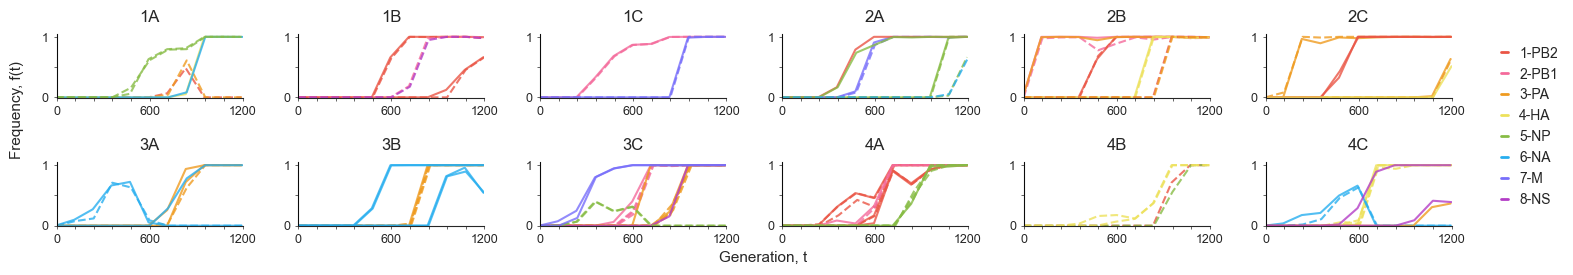

In [24]:
fig = plt.figure(figsize=(18, 2.5))
max_panels = 12
gs = gridspec.GridSpec(2,6, wspace=0.3, hspace=1)

offset = 0.5 

for i, population in enumerate(populations):
     
    df = driver_passenger_pairs[driver_passenger_pairs["population"]==population].set_index(["driver refname", "driver nucpos", "driver snv"])
    ax = fig.add_subplot(gs[i])
    
    plotted = []
    
    for j, (driver_refname, driver_nucpos, driver_snv) in enumerate(df.index.unique()):
        if (driver_refname, driver_nucpos, driver_snv) not in plotted:
            freqs = trajectories.loc[(population, driver_refname, driver_nucpos, driver_snv)].values.tolist()
            ax.plot([p-offset for p in passages], freqs, lw=1.5, alpha=0.8, color=segment_cpal[segments.index(driver_refname)])
            plotted.append((driver_refname, driver_nucpos, driver_snv))
        
        sdf = df.loc[[(driver_refname, driver_nucpos, driver_snv)]].reset_index().set_index(['passenger refname', 'passenger nucpos', 'passenger snv'])
        for k, (passenger_refname, passenger_nucpos, passenger_snv) in enumerate(sdf.index):
            if (passenger_refname, passenger_nucpos, passenger_snv) not in plotted:
                freqs = trajectories.loc[(population, passenger_refname, passenger_nucpos, passenger_snv)].values.tolist()
                ax.plot([p+(offset*k) for p in passages], freqs, lw=1.5, alpha=0.8, color=segment_cpal[segments.index(driver_refname)], ls="--")
                plotted.append((passenger_refname, passenger_nucpos, passenger_snv))
            
    for j, snv_list in enumerate(potential_epistatic_interactions[population]):
        
        for k, (refname, nucpos, snv) in enumerate(snv_list):
            if (refname, nucpos, snv) not in plotted:
                freqs = trajectories.loc[(population, refname, nucpos, snv)].values.tolist()
                ls = "-" if snv in non_synonymous_dict[refname] else "--"
                ax.plot([p+(offset*k)-offset for p in passages], freqs, lw=1.5, color=segment_cpal[segments.index(refname)], alpha=0.8, ls=ls )
                plotted.append((refname, nucpos, snv))
         
    ax.spines[['top','right']].set_visible(False)
    ax.set_xlim(-0, passages[-1])
    ax.axvline(0, color="black", zorder=100, lw=0.5)
    
    ax.set_ylim(-0.01,1.05)
    ax.set_yticks([0, 0.5, 1.0])
    ax.set_yticklabels(["0", "", "1"], size=9)


    ax.set_xticks(passages)
    ax.set_xticklabels([])
    ax.tick_params(axis='both', which='both', length=2)  
    ax.set_xticklabels([int((p*hours_per_passage)/generation_time) if p%50==0 else "" for p in passages], size=9)
        
    if i == 8:
        ax.text(120, -0.6, "Generation, t", size=11, ha="center")
    if i ==0:
        ax.text(-25, -0.2, "Frequency, f(t)", size=11, rotation=90, va="center")
        
    ax.text(50,1.2, population, ha="center", va="bottom", size=12)

    if i==5:
        ax.legend(handles=segment_legend_elements, loc='upper left', bbox_to_anchor=(1.2,1), ncols =1, fontsize=10, handlelength=0.5,
                                edgecolor=None, frameon=False, columnspacing=0.5)    


### 3.2.  Linkage disequillibrium for cooccurring pairs on the same segment

In [25]:
same_segment_cooccurring_pairs  = cooccurring_pairs [cooccurring_pairs ["refname 1"]==cooccurring_pairs ["refname 2"]].reset_index(drop=True)

#### 3.2.1. Run haplotype reconstruction and get results

In [26]:
if run:
    n_threads = 1 #recommend keeping at one > each command is already segment specific 
    cmd_list = []

    prep_df = snv_complete_overview.copy().reset_index().set_index(["population", "passage", "refname"]).sort_index()

    for i, row in same_segment_cooccurring_pairs.iterrows():
        population, refname = row.iloc[0], row.iloc[2]
        donor, replicate = population
        donor = int(donor)
        
        snv1 = tuple(row[3:5])
    
        snv2 = tuple(row[7:9])
        

        #get trajectory of snv1 and passenger
        df = trajectories.loc[(population, refname)].loc[[snv1, snv2]]


        #reconstruction haploptype for each passage in which at least one of the SNVs has a frequency 
        for passage in passages[1:]:
            sample = f"P{passage}-{population}"
            samp_dir =  os.path.join(haplotype_cooccurence_results_dir, sample)
                
            if len(df[df[passage]>0])>0:
                
                nucpos_list = df[df[passage]>0].index.get_level_values(0).tolist()
                vdf = prep_df.loc[(population, passage, refname)].reset_index()
                vdf = vdf[vdf["nucpos"].isin(nucpos_list)]
                vdf["refname"] = refname
                
                for tr in tech_reps:
                    tdf = vdf[["refname", "nucpos", "snv", "read_base", f"coverage|tr{tr}", f"nuc_count|tr{tr}", f"nuc_freq|tr{tr}"]]
                    tdf = tdf.rename(columns={c:c.split("|")[0] for c in tdf.columns})
                    
                    fn = f"P{passage}_{population}_{refname}_{snv1[-1]}_{snv2[-1]}_{tr}.csv"
                    fn = os.path.join(haplotype_cooccurence_input_dir, fn)
                    
                    tdf.to_csv(fn, index=False)
                    
                    coverage_file = os.path.join(coverage_dir, f"nuc_coverge_P{passage}-{population}_{tr}.csv")
                    read_files = [os.path.join(align_dir,  f'{sample}_{tr}_reads.json.jz')]
                    
                    cmd = ['python', './scripts/haplotype_reconstruction.py', '-s', fn.replace("../", "./"), '-c', coverage_file.replace("../", "./"), '-r', " ".join([f.replace("../", "./") for f in read_files]), 
                '-o', samp_dir.replace("../", "./"), '-t', str(n_threads), '-sn', f"P{passage}_{population}_{refname}_{snv1[-1]}_{snv2[-1]}_{tr}",]

                    cmd_list.append(" ".join(cmd))

    with open(haplotype_cooccurence_bash_script, "w") as fw:
        fw.write("#!/bin/bash\n")
        fw.write('cd ~/LTEE-flu\n\n') #change to actual location of the repo
        for cmd in cmd_list:
            fw.write(f"{cmd}\n")
                        

In [27]:
if run:
    cooccurring_haplotypes = []

    prep_df = snv_complete_overview.copy().reset_index().set_index(["population", "passage", "refname"]).sort_index()

    for i, row in same_segment_cooccurring_pairs.iterrows():
        population, refname = row.iloc[0], row.iloc[2]
        donor, replicate = population
        donor = int(donor)
        
        non_syn = row.iloc[1]
        
        mut1 = tuple(row.iloc[3:5])
        mut2 = tuple(row.iloc[7:9])
        
        #get trajectory of mut1 and mut2
        df = trajectories.loc[(population, refname)].loc[[mut1, mut2]]
        
        haplotype_df = []
        for passage in passages[1:]:
            if len(df[df[passage]>0])>0:
                
                vdf = prep_df.loc[(population, passage, refname)].reset_index()
                vdf = vdf[vdf["nucpos"].isin(nucpos_list)]
            
                fn = f"P{passage}_{population}_{refname}_{mut1[-1]}_{mut2[-1]}_{tr}.csv"
                fn = os.path.join(haplotype_cooccurence_input_dir, fn)
                sample = f"P{passage}_{population}_{refname}_{mut1[-1]}_{mut2[-1]}"
                
                #technical replicate 1
                try:
                    observed_haplotypes_1, observed_haplotype_frequencies_1 = get_cooccur_haplotypes (refname, fn, haplotype_cooccurence_dir, f"{sample}", 1, segment_nuc_cds[refname])
                except:
                    observed_haplotypes_1, observed_haplotype_frequencies_1 = [], []
                    
                #technical replicate 2
                try:
                    observed_haplotypes_2, observed_haplotype_frequencies_2 = get_cooccur_haplotypes (refname, fn, haplotype_cooccurence_dir, f"{sample}", 2, segment_nuc_cds[refname])
                except:
                    observed_haplotypes_2, observed_haplotype_frequencies_2 = [], []
                    
                #only caring about haplotypes observed above the detection limit    
                observed_haplotypes, observed_haplotype_frequencies = [], []
                for haplotype, freq in zip(observed_haplotypes_1, observed_haplotype_frequencies_1):

                    if haplotype in observed_haplotypes_2:
                        #estimated the frequency dist so cannot do binominial estimation
                        i = observed_haplotypes_2.index(haplotype)
                        freq = round(np.mean([freq, observed_haplotype_frequencies_2[i]]),4)
                        if freq>=detection_limit: 
                            observed_haplotypes.append(haplotype)
                            observed_haplotype_frequencies.append(freq)
                    else:
                        # no observed so 0 ? 
                        freq = round(np.mean([freq,0]),4)
                        if freq >= detection_limit:
                            observed_haplotypes.append(haplotype)
                            observed_haplotype_frequencies.append(freq)

                for haplotype, freq in zip(observed_haplotypes_2, observed_haplotype_frequencies_2):
                    if haplotype not in observed_haplotypes_1:
                        freq= round(np.mean([freq,0]),4)
                        if freq >= detection_limit:
                            observed_haplotypes.append(haplotype)
                            observed_haplotype_frequencies.append(freq)
                        
                
                for haplotype,freq in zip(observed_haplotypes, observed_haplotype_frequencies):
                    haplotype_df.append([passage, haplotype, freq])
                    
        haplotype_df = pd.DataFrame.from_records(haplotype_df, columns=["passage", "haplotype", "frequency"])
        
        filler_df = []
        for passage in passages:
            if passage not in haplotype_df["passage"].tolist():
                filler_df.append([passage, tuple(), 1.0])
        filler_df = pd.DataFrame.from_records(filler_df, columns=haplotype_df.columns)
        haplotype_df = pd.concat([haplotype_df, filler_df], ignore_index=True)
        haplotype_df = haplotype_df.pivot(index="haplotype", columns="passage", values="frequency").fillna(0)
        
        haplotype_df.columns.name= None
        haplotype_df[["population", "non_synonymous", "refname", "mut1", "mut2"]] = [population,  non_syn, refname, mut1[-1], mut2[-1]]
        haplotype_df = haplotype_df.reset_index().set_index(["population", "non_synonymous", "refname", "mut1", "mut2", "haplotype"])

        try:
            cooccurring_haplotypes = pd.concat([cooccurring_haplotypes, haplotype_df])
        except:
            cooccurring_haplotypes = haplotype_df

    cooccurring_haplotypes = cooccurring_haplotypes.sort_index()

    #copy to export
    df = cooccurring_haplotypes.copy().reset_index()
    df["haplotype"] = [",".join(list(h)) for h in df["haplotype"]]
    df.to_csv(cooccurence_haplotype_file, index=False)

In [28]:
if not run:
    cooccurring_haplotypes = pd.read_csv(cooccurence_haplotype_file)
    cooccurring_haplotypes["haplotype"] = [tuple() if pd.isna(h) else tuple(h.split(",")) for h in cooccurring_haplotypes["haplotype"]]
    cooccurring_haplotypes = cooccurring_haplotypes.set_index(['population', 'non_synonymous', 'refname', 'mut1', 'mut2', 'haplotype']).sort_index()
    cooccurring_haplotypes = cooccurring_haplotypes.rename(columns={c:int(c) for c in cooccurring_haplotypes.columns})


#### 3.2.2. Calculate Linkage Disequillibrium

In [29]:
cooccurring_linkage_disequillibrium = []
for i, row in same_segment_cooccurring_pairs.iterrows():
    population, non_syn, refname = row[0:3]
    donor, replicate = population
    donor = int(donor)
    
    mut1 = tuple(row[3:5])
    mut2 = tuple(row[7:9])
    
    #get trajectory of mut1 and mut2
    df = trajectories.loc[(population, refname)].loc[[mut1, mut2]].sort_index()
    hdf = cooccurring_haplotypes.loc[(population, non_syn, refname, mut1[-1], mut2[-1])]
    mut1_mut2_haplotype = tuple([v[-1] for v in sorted([mut1, mut2])])
    
    cooc_ns_detected = False
    for passage in passages:
        if len(df[df[passage]>0]) == len(df) and len(df[df[passage]>0.95]) == 0:
            cooc_ns_detected = True

            mut1_freq = df.loc[mut1, passage] 
            mut2_freq = df.loc[mut2, passage]
            
            #indexing by tuple is giving issues so this is a work-around
            try:
                haplotype_idx = [j for j, haplo in enumerate(hdf.index.tolist()) if haplo==mut1_mut2_haplotype][0]
                haplotype_freq = hdf.iloc[haplotype_idx].to_dict()[passage]
                
            except:
                haplotype_freq = 0
            
            
            #D = Pab - PaPb
            linkage_D = haplotype_freq - (mut1_freq*mut2_freq)
            if linkage_D > 0:
                linkage_D_max = min([mut1_freq*(1-mut2_freq), mut2_freq*(1-mut1_freq)])
            else:
                linkage_D_max = max([-(mut1_freq*mut2_freq), -(1-mut1_freq)*(1-mut2_freq)])
            linkage_D_prime = linkage_D/linkage_D_max
                
            linkage_r2 = (linkage_D**2)/((mut1_freq*(1-mut1_freq))*(mut2_freq*(1-mut2_freq)))
            #print (linkage_D, linkage_r2)
            cooccurring_linkage_disequillibrium.append([population, non_syn, refname, mut1[-1], mut2[-1], passage, haplotype_freq, mut1_freq, mut2_freq, 
                                                       round(linkage_D,3), round(linkage_D_prime,3), round(linkage_r2,3),  True if linkage_D_prime >= Dprime_cutoff else False])# and linkage_r2>= ld_r2_cutoff else False])
            break
            
    if not cooc_ns_detected:
        cooccurring_linkage_disequillibrium.append([population, non_syn, refname, mut1[-1], mut2[-1], np.nan, np.nan, np.nan, np.nan, np.nan, np.nan,np.nan])
        
cooccurring_linkage_disequillibrium = pd.DataFrame.from_records(cooccurring_linkage_disequillibrium, columns=["population", "non_synonymous", "refname", "snv 1", "snv 2", "passage first detected", "haplotype_freq",
                                                                                                            "snv 1_freq", "snv 2_freq", "D", "D'", "r2",  "sufficient LD support"])
cooccurring_linkage_disequillibrium = cooccurring_linkage_disequillibrium.set_index(["population", "refname", "snv 1", "snv 2"])


## 4. Annotate results in SNV summary

In [30]:
#synonymous hitchhiking snvs

snv_summary = snv_summary.reset_index().set_index(["population", "refname", "nucpos", "snv", "protein", "aapos", "aa_mut"])

driver_passenger_pairs = driver_passenger_pairs.set_index(["population", "passenger refname", "passenger nucpos", "passenger snv"])
hitchhiker_linkage_disequillibrium = hitchhiker_linkage_disequillibrium.reset_index().set_index(["population", "refname", "passenger"]).sort_index()

for (population, refname, nucpos, snv, protein, aapos, aa_mut), row in snv_summary.iterrows():
    if (population, refname, nucpos, snv) in driver_passenger_pairs.index.tolist():
        if (population, refname, snv) in hitchhiker_linkage_disequillibrium.index.tolist():
            if True in hitchhiker_linkage_disequillibrium.loc[[(population, refname, snv)]]["sufficient LD support"].tolist():
                if row["non_synonymous"] == False:
                    snv_summary.loc[(population, refname, nucpos, snv, protein, aapos, aa_mut), "hitchhiker"] = "high confidence"
                else:#assuming that the other co-occuring SNV will be caught in the co-occurrence detection
                    snv_summary.loc[(population, refname, nucpos, snv, protein, aapos, aa_mut), "cooccurence"] = "high confidence"
                        
            else:
                if row["non_synonymous"] == False:
                    snv_summary.loc[(population, refname, nucpos, snv, protein, aapos, aa_mut), "hitchhiker"] = "potential"
                else:
                    snv_summary.loc[(population, refname, nucpos, snv, protein, aapos, aa_mut), "cooccurence"] = "potential"
                    
        else:
            if row["non_synonymous"] == False:
                snv_summary.loc[(population, refname, nucpos, snv, protein, aapos, aa_mut), "hitchhiker"] = "potential"
            else:
                snv_summary.loc[(population, refname, nucpos, snv, protein, aapos, aa_mut), "cooccurence"] = "potential"
                

driver_passenger_pairs = driver_passenger_pairs.reset_index()
hitchhiker_linkage_disequillibrium = hitchhiker_linkage_disequillibrium.reset_index().set_index(["population", "refname", "driver",  "passenger", ])

snv_summary = snv_summary.reset_index().set_index(["population", "refname", "nucpos", "snv",]).sort_index()


In [31]:
#cooccurring non-synonymous snvs
for i, row in cooccurring_pairs.iterrows():
    population = row.iloc[0] 
    refname1, nucpos1, snv1 = row.iloc[2:5]
    refname2, nucpos2, snv2 = row.iloc[6:9]
    
    if refname1 ==refname2 and (population, refname1, snv1, snv2) in cooccurring_linkage_disequillibrium.index.tolist():
        if cooccurring_linkage_disequillibrium.loc[(population, refname1, snv1, snv2), "sufficient LD support"]:
            snv_summary.loc[(population, refname1, nucpos1, snv1), "cooccurence"] = "high confidence"
            snv_summary.loc[(population, refname2, nucpos2, snv2), "cooccurence"] = "high confidence"
        else:
            snv_summary.loc[(population, refname1, nucpos1, snv1), "cooccurence"] = "potential"
            snv_summary.loc[(population, refname2, nucpos2, snv2), "cooccurence"] = "potential"
    else:
        snv_summary.loc[(population, refname1, nucpos1, snv1), "cooccurence"] = "potential"
        snv_summary.loc[(population, refname2, nucpos2, snv2), "cooccurence"] = "potential"



snv_summary = snv_summary.reset_index().set_index(["population", "refname", "nucpos", "snv"])            

In [32]:
snv_summary.to_csv("../results/snv_summary_annotated_linkage.csv")

## 5. Visualize

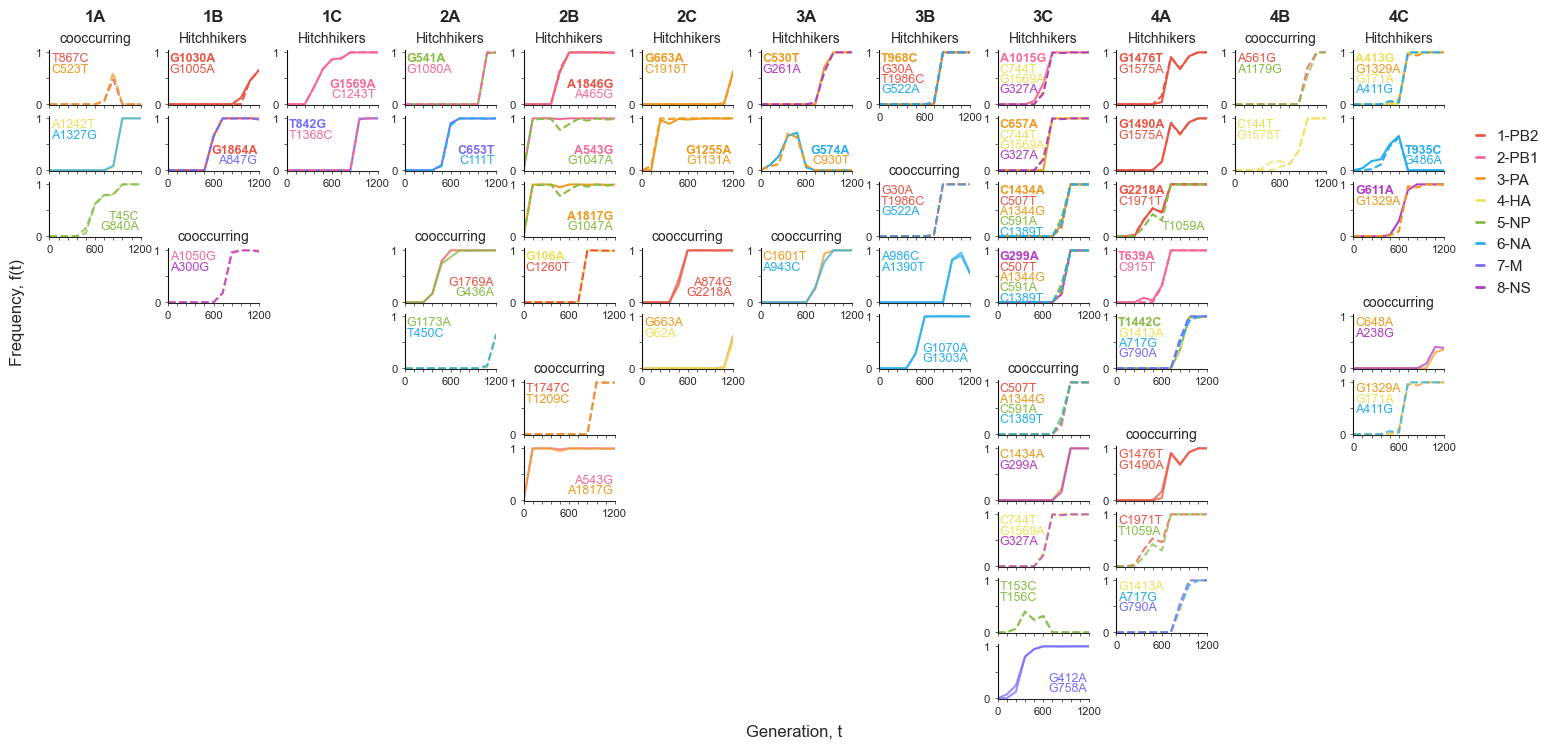

In [33]:
fig = plt.figure(figsize=(18, 12))
max_panels = 12
gs = gridspec.GridSpec(1,12, wspace=0.3, hspace=0.2)

for i, population in enumerate(populations):
     
    df = driver_passenger_pairs[driver_passenger_pairs["population"]==population].set_index(["driver refname", "driver nucpos", "driver snv"])
    

    sl = potential_epistatic_interactions[population]
    n_actual_panels = len(df.index.unique()) + len(sl)
    
    #ensuring that each actual plot it the same size
    #massive cooking here, dont know what it does but works so not changing it 
    h_ratios = []
    sep = 0
    for x in df.index.unique():
        h_ratios.extend([1,0.2])
    if len(h_ratios) >0:
        h_ratios.extend([1.2])
        sep+= 1
    for x in sl:
        h_ratios.extend([1,0.2])
    if len(sl) >0:
        h_ratios.extend([1.2])
        sep+= 1
    for x in range(max_panels-n_actual_panels):
        h_ratios.extend([1,0.2])
    while sep<2:
        h_ratios.extend([1.2])
        sep+=1
        
    panel_indices = [x for x, h in enumerate(h_ratios) if h==1]
    panel_tracker = -1
    gsi = gridspec.GridSpecFromSubplotSpec(len(h_ratios),1, wspace=0., hspace=0, subplot_spec=gs[i], height_ratios=h_ratios)
    
    total_axes = []
    annotated_axes = []
    if len(df) > 0:
        axes = []
        for j, (driver_refname, driver_nucpos, driver_snv) in enumerate(df.index.unique()):
            
            panel_tracker+= 1
            sdf = df.loc[[(driver_refname, driver_nucpos, driver_snv)]].set_index(["passenger refname","passenger nucpos", "passenger snv"]).sort_index()
            ax = fig.add_subplot(gsi[panel_indices[panel_tracker]])
            axes.append(ax)
            total_axes.append(ax)
            
            freqs = trajectories.loc[(population, driver_refname, driver_nucpos, driver_snv)].values.tolist()
            ax.plot(passages, freqs, lw=1.5, alpha=1, color=segment_cpal[segments.index(driver_refname)])
            if freqs[1] < 0.5 and freqs[5]< 0.5 and driver_snv not in ["G574A"]:
                ax.text(2, 1.0, f"{driver_snv}", size=9, color=segment_cpal[segments.index(driver_refname)], va="top", fontweight="bold") 
            else:
                ax.text(98, 0.5, f"{driver_snv}", size=9, color=segment_cpal[segments.index(driver_refname)], va="top", fontweight="bold", ha="right") 

            for k, idx in enumerate(sdf.index.unique()):
                freqs = trajectories.loc[(population)].loc[idx].values.tolist()
                ax.plot(passages, freqs, lw=1.5, alpha=1, color=segment_cpal[segments.index(idx[0])], ls="--")
                
                if idx[-1] in ["T1059A"]:
                    ax.text(98, 0.5-((k)*0.2), f"{idx[-1]}", size=9, color=segment_cpal[segments.index(idx[0])], va="top", ha="right") 
                 
                elif freqs[1] < 0.5 and freqs[5]< 0.5 and idx[-1] not in ["C930T"]:
                    ax.text(2, 1.0-((k+1)*0.2), f"{idx[-1]}", size=9, color=segment_cpal[segments.index(idx[0])], va="top", ) 
                    
                else:
                    ax.text(98, 0.5-((k+1)*0.2), f"{idx[-1]}", size=9, color=segment_cpal[segments.index(idx[0])], va="top", ha="right") 
        axes[-1].set_xticks(passages)
        axes[-1].set_xticklabels([int((p*hours_per_passage)/generation_time) if p%50==0 else "" for p in passages], size=8)
        annotated_axes.append(axes[-1])
        axes[0].text(50, 1.2, "Hitchhikers", ha="center", size=10,)
        
            
    if len(sl): 
        axes = []
        
        gsij = gridspec.GridSpecFromSubplotSpec(len(sl),1, wspace=0.1, hspace=0.23, subplot_spec=gsi[1])
        for j, snv_list in enumerate(potential_epistatic_interactions[population]):
            panel_tracker+= 1
            ax = fig.add_subplot(gsi[panel_indices[panel_tracker]])
            axes.append(ax)
            total_axes.append(ax)
            
            for k, (refname, nucpos, snv) in enumerate(snv_list):
                freqs = trajectories.loc[(population, refname, nucpos, snv)].values.tolist()
                ls = "-" if snv in non_synonymous_dict[refname] else "--"
                ax.plot(passages, freqs, lw=1.5, color=segment_cpal[segments.index(refname)], alpha=0.75, ls=ls )
                if freqs[1] < 0.5 and freqs[5]< 0.5:
                    ax.text(2, 1.0-((k)*0.2), f"{snv}", size=9, color=segment_cpal[segments.index(refname)], va="top") 
                    
                else:
                    ax.text(98, 0.5-((k)*0.2), f"{snv}", size=9, color=segment_cpal[segments.index(refname)], va="top", ha="right") 
        axes[-1].set_xticks(passages)
        axes[-1].set_xticklabels([int((p*hours_per_passage)/generation_time) if p%50==0 else "" for p in passages], size=8)
        annotated_axes.append(axes[-1])
        axes[0].text(50, 1.2, "cooccurring", ha="center", size=10, )
                 
    for ax in total_axes:
        ax.spines[['top','right']].set_visible(False)
        ax.set_xlim(-0, passages[-1])
        ax.axvline(0, color="black", zorder=100, lw=0.5)
        
        ax.set_ylim(-0.01,1.05)
        ax.set_yticks([0, 0.5, 1.0])
        ax.set_yticklabels(["0", "", "1"], size=8)

        if ax not in annotated_axes:
            ax.set_xticks(passages)
            ax.set_xticklabels([])
        ax.tick_params(axis='both', which='both', length=2)  
    
    
    total_axes[0].text(50, 1.6, population, ha="center", size=12, fontweight="bold")
    if i == 0:
        total_axes[0].text(-35, -4, "Frequency, f(t)", ha="center", va="center", rotation = 90,size=12 )
    if i == 9:
        total_axes[-1].text(-300, -2, "Generation, t", ha="right", size=12 )     
             
    if i == 11:
        leg = total_axes[-4].legend(handles=segment_legend_elements, loc='upper left', bbox_to_anchor=(1.2,1), ncols =1, fontsize=11, handlelength=0.5,
                                edgecolor=None, frameon=False, columnspacing=0.5)    
        
        

Text(0.98, 0.1, '* = suffient LD support')

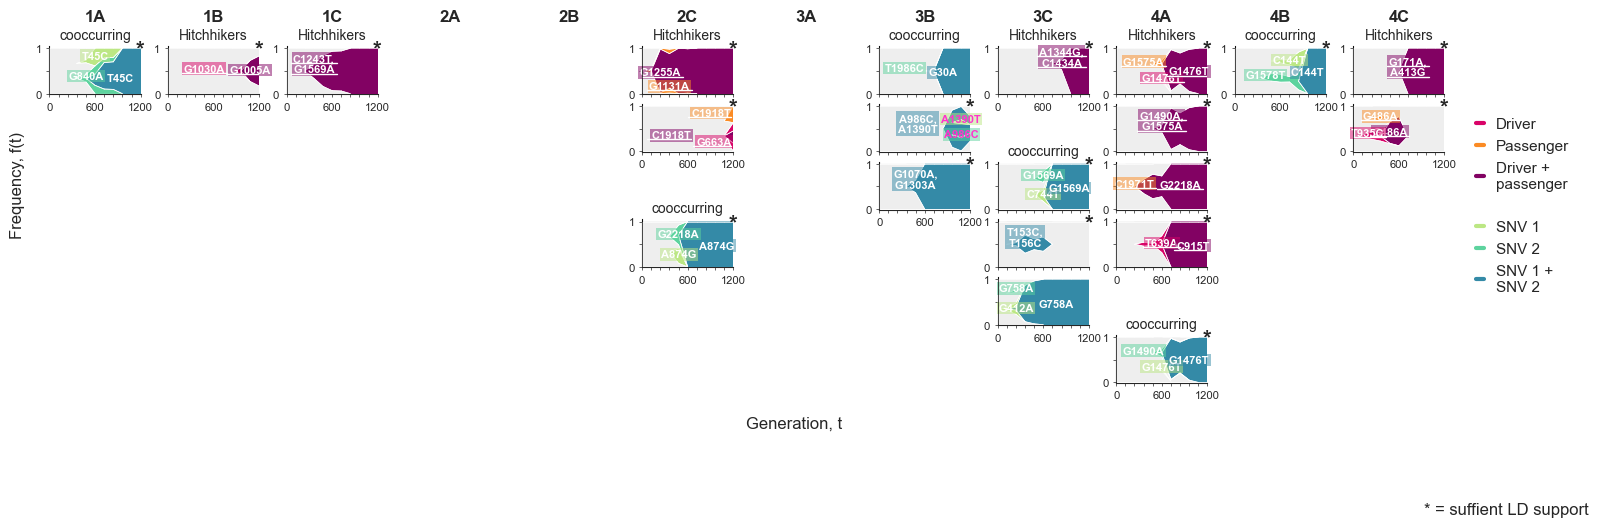

In [34]:
fig = plt.figure(figsize=(18, 6))
max_panels = 6
gs = gridspec.GridSpec(1,12, wspace=0.3, hspace=0.2)




legend_elements = []#[Line2D([0], [0], color='white', label="population", linewidth=0,)
for color, label in zip([driver_col,passenger_col, haplotype_col, "white", snv1_col,snv2_col, haplotype_cooc_col,], 
                        ["Driver", "Passenger", "Driver +\npassenger", "", "SNV 1", "SNV 2", "SNV 1 +\nSNV 2"]):
    legend_elements.append(Line2D([0], [0], color=color, label=label, linewidth=3,  ))


for i, population in enumerate(populations):
    
    hitch = same_segment_driver_passenger_pairs[same_segment_driver_passenger_pairs["population"]==population].set_index(["driver refname", "driver snv", "passenger snv"]).sort_index()
    cooc = same_segment_cooccurring_pairs[same_segment_cooccurring_pairs["population"]==population]
    cooc = cooc.set_index(["non_synonymous", "refname 1", "snv 1", "snv 2"]).sort_index()
    
    n_actual_panels = len(hitch) + len(cooc)
    if n_actual_panels < 1: 
        #fig.text(i/len(simplified_populations), 0.95, population)
        gsi = gridspec.GridSpecFromSubplotSpec(len(h_ratios),1, wspace=0., hspace=0, subplot_spec=gs[i], height_ratios=h_ratios)
        ax = fig.add_subplot(gsi[0])
        ax.set_ylim(-0.01,1.05)
        ax.set_xlim(-0, timepoints[-1])
        ax.text(50, 1.6, population, ha="center", size=12, fontweight="bold")
        ax.axis('off')
        
        continue
    
    #ensuring that each actual plot it the same size
    #massive cooking here, dont know what it does but works so not changing it 
    h_ratios = []
    sep = 0
    for x in hitch.index.unique():
        h_ratios.extend([1,0.2])
    if len(h_ratios) >0:
        h_ratios.extend([1.2])
        sep+= 1
    for x in cooc.index.unique():
        h_ratios.extend([1,0.2])
    if len(cooc) >0:
        h_ratios.extend([1.2])
        sep+= 1
    for x in range(max_panels-n_actual_panels):
        h_ratios.extend([1,0.2])
    while sep<2:
        h_ratios.extend([1.2])
        sep+=1

        
    panel_indices = [x for x, h in enumerate(h_ratios) if h==1]
    panel_tracker = -1
    gsi = gridspec.GridSpecFromSubplotSpec(len(h_ratios),1, wspace=0., hspace=0, subplot_spec=gs[i], height_ratios=h_ratios)
    
    total_axes = []
    annotated_axes = []
    if len(hitch)>0:
        axes = []
        for j, (refname, driver, passenger) in enumerate(hitch.index.unique()):
            panel_tracker+= 1
            ax = fig.add_subplot(gsi[panel_indices[panel_tracker]])
            axes.append(ax)
            total_axes.append(ax)
            
            haplotype_df = hitchhiker_haplotypes.loc[(population, refname, driver, passenger)]
            
            timepoints = passages
            haplotype_order = get_haplotype_order(haplotype_df, timepoints)
            haplotype_plotdf = generate_haplotype_plotting_df(haplotype_df, timepoints, haplotype_order, detection_limit=0.02)
            haplotype_appearance= get_haplotype_appearance(haplotype_df)
            
            color_list = []
            for haplo in haplotype_order:
                if haplo == tuple([]):#wildtype
                    color_list.append(wt_color)
                elif haplo == tuple([driver]):
                    color_list.append(driver_col)
                elif haplo == tuple([passenger]):
                    color_list.append(passenger_col)
                else:
                    color_list.append(haplotype_col)
            haplotype_color_dict = {haplotype:color_list[i] for i, haplotype in enumerate(haplotype_order)}

                    
            p = muller_plot(ax, timepoints, haplotype_plotdf.T, haplotype_order, haplotype_appearance, alpha=1, edgecolor="white", custom_color_list=color_list)
            
            
            hdf = haplotype_df.copy()
            for idx, (_, row) in enumerate(hdf.iterrows()):
                for c, v in enumerate(row.values):
                    if v < 0.02:
                        hdf.iloc[idx, c] = 0.0
            hdf = hdf.iloc[[idx for idx, (_, row) in enumerate(hdf.iterrows()) if sum(row.values)>0]]
            texts = annotate_muller_plot(ax, hdf, haplotype_plotdf, {driver:True, passenger:False}, haplotype_color_dict, 8)
            resolve_text_overlaps(ax, texts, padding=1)
            highlight_non_synonymous_snvs(ax,texts,{driver:True, passenger:False})
            
            if hitchhiker_linkage_disequillibrium.loc[(population, refname, driver, passenger), "sufficient LD support"]:
                ax.text(95, 0.75, "*", fontweight="bold", va="bottom", size=16)
            
        axes[-1].set_xticks(passages)
        axes[-1].set_xticklabels([int((p*hours_per_passage)/generation_time) if p%50==0 else "" for p in passages], size=8)
        annotated_axes.append(axes[-1])
        axes[0].text(50, 1.2, "Hitchhikers", ha="center", size=10,)
        
    if len(cooc) >0:
        axes = []
        for j, (non_syn, refname, snv1, snv2) in enumerate(cooc.index):
            panel_tracker+= 1
            ax = fig.add_subplot(gsi[panel_indices[panel_tracker]])
            axes.append(ax)
            total_axes.append(ax)
            
            haplotype_df = cooccurring_haplotypes.loc[(population, non_syn, refname, snv1, snv2)]
            timepoints = passages
            haplotype_order = get_haplotype_order(haplotype_df, timepoints)
            haplotype_plotdf = generate_haplotype_plotting_df(haplotype_df, timepoints, haplotype_order, detection_limit=0.02)
            haplotype_appearance= get_haplotype_appearance(haplotype_df)
            
            color_list = []
            for haplo in haplotype_order:
                if haplo == tuple([]):#wildtype
                    color_list.append(wt_color)
                elif haplo == tuple([snv1]):
                    color_list.append(snv1_col)
                elif haplo == tuple([snv2]):
                    color_list.append(snv2_col)
                else:
                    color_list.append(haplotype_cooc_col)
            haplotype_color_dict = {haplotype:color_list[i] for i, haplotype in enumerate(haplotype_order)}
            
            color_list
            p = muller_plot(ax, timepoints, haplotype_plotdf.T, haplotype_order, haplotype_appearance, alpha=1, edgecolor="white", custom_color_list=color_list)
            
            
            hdf = haplotype_df.copy()
            for idx, (_, row) in enumerate(hdf.iterrows()):
                for c, v in enumerate(row.values):
                    if v < 0.02:
                        hdf.iloc[idx, c] = 0.0
            hdf = hdf.iloc[[idx for idx, (_, row) in enumerate(hdf.iterrows()) if sum(row.values)>0]]
            texts = annotate_muller_plot(ax, hdf, haplotype_plotdf, {driver:True, passenger:False}, haplotype_color_dict, 8)
            resolve_text_overlaps(ax, texts, padding=1)
            highlight_non_synonymous_snvs(ax,texts,{driver:True, passenger:False})
            
            if cooccurring_linkage_disequillibrium.loc[(population, refname, snv1, snv2), "sufficient LD support"]:
                ax.text(95, 0.75, "*", fontweight="bold", va="bottom", size=16,)
            
        axes[-1].set_xticks(passages)
        axes[-1].set_xticklabels([int((p*hours_per_passage)/generation_time) if p%50==0 else "" for p in passages], size=8)
        annotated_axes.append(axes[-1])
        axes[0].text(50, 1.2, "cooccurring", ha="center", size=10,)
                
    for ax in total_axes:
        ax.spines[['top','right']].set_visible(False)
        ax.set_xlim(-0, timepoints[-1])
        ax.axvline(0, color="black", zorder=100, lw=0.5)
        
        ax.set_ylim(-0.01,1.05)
        ax.set_yticks([0, 0.5, 1.0])
        ax.set_yticklabels(["0", "", "1"], size=8)

        if ax not in annotated_axes:
            ax.set_xticks(passages)
            ax.set_xticklabels([])
        ax.tick_params(axis='both', which='both', length=2)  
    
    total_axes[0].text(50, 1.6, population, ha="center", size=12, fontweight="bold")
    if i == 0:
        total_axes[0].text(-35, -2, "Frequency, f(t)", ha="center", va="center", rotation = 90,size=12 )
    if i == 9:
        total_axes[-1].text(-300, -1, "Generation, t", ha="right", size=12 )                 
            
    if i == 11:
        leg = total_axes[-1].legend(handles=legend_elements, loc='upper left', bbox_to_anchor=(1.2,1), ncols =1, fontsize=11, handlelength=0.5,
                                edgecolor=None, frameon=False, columnspacing=0.5)
        

fig.text(0.98, 0.1, "* = suffient LD support", ha="right", size=12)  

        
         

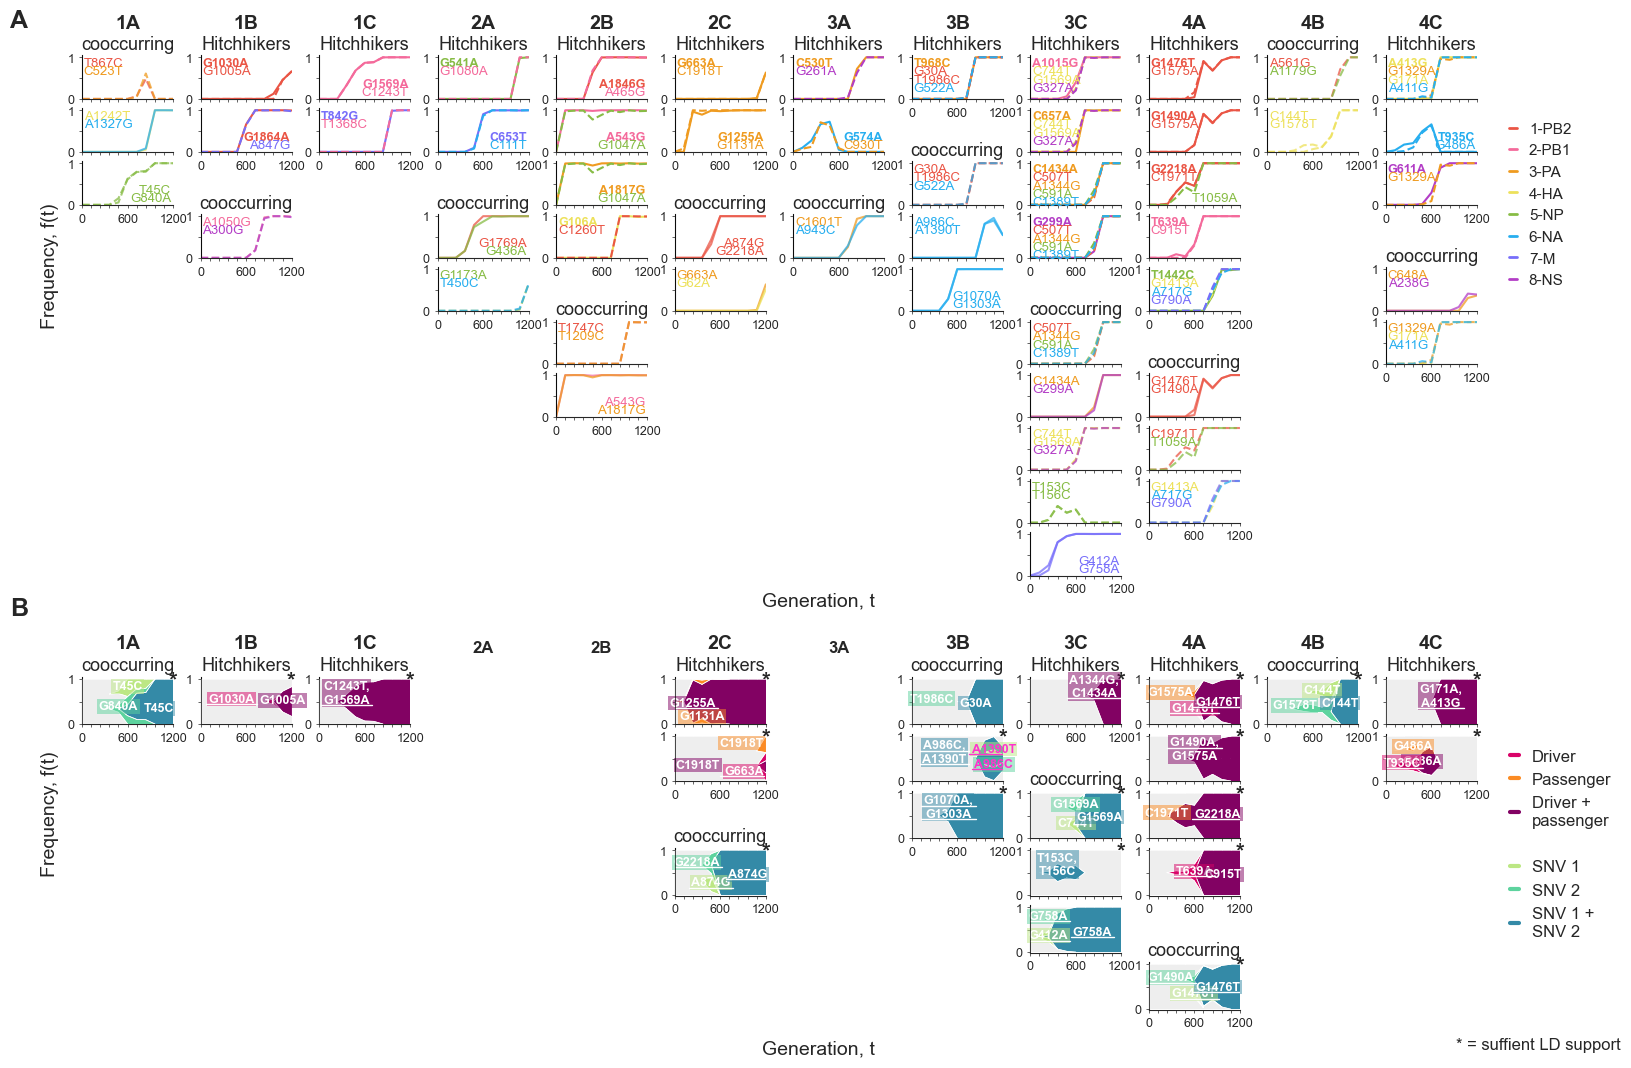

In [35]:

fig = plt.figure(figsize=(18, 14))
max_panels = 12
gs_base = gridspec.GridSpec(2,1, wspace=0., hspace=-0.2, height_ratios=[13,8])

### frequency plot 
gs = gridspec.GridSpecFromSubplotSpec(1,12,wspace=0.3, hspace=0.3, subplot_spec=gs_base[0])

for i, population in enumerate(populations):
     
    df = driver_passenger_pairs[driver_passenger_pairs["population"]==population].set_index(["driver refname", "driver nucpos", "driver snv"])

    sl = potential_epistatic_interactions[population]
    n_actual_panels = len(df.index.unique()) + len(sl)
    
    #ensuring that each actual plot it the same size
    #massive cooking here, dont know what it does but works so not changing it 
    h_ratios = []
    sep = 0
    for x in df.index.unique():
        h_ratios.extend([1,0.2])
    if len(h_ratios) >0:
        h_ratios.extend([1.2])
        sep+= 1
    for x in sl:
        h_ratios.extend([1,0.2])
    if len(sl) >0:
        h_ratios.extend([1.2])
        sep+= 1
    for x in range(max_panels-n_actual_panels):
        h_ratios.extend([1,0.2])
    while sep<2:
        h_ratios.extend([1.2])
        sep+=1
        
    panel_indices = [x for x, h in enumerate(h_ratios) if h==1]
    panel_tracker = -1
    gsi = gridspec.GridSpecFromSubplotSpec(len(h_ratios),1, wspace=0., hspace=0, subplot_spec=gs[i], height_ratios=h_ratios)
    
    total_axes = []
    annotated_axes = []
    if len(df) > 0:
        axes = []
        for j, (driver_refname, driver_nucpos, driver_snv) in enumerate(df.index.unique()):
            
            panel_tracker+= 1
            sdf = df.loc[[(driver_refname, driver_nucpos, driver_snv)]].set_index(["passenger refname","passenger nucpos", "passenger snv"]).sort_index()
            ax = fig.add_subplot(gsi[panel_indices[panel_tracker]])
            axes.append(ax)
            total_axes.append(ax)
            
            freqs = trajectories.loc[(population, driver_refname, driver_nucpos, driver_snv)].values.tolist()
            ax.plot(passages, freqs, lw=1.5, alpha=1, color=segment_cpal[segments.index(driver_refname)])
            if freqs[1] < 0.5 and freqs[5]< 0.5 and driver_snv not in ["G574A"]:
                ax.text(2, 1.0, f"{driver_snv}", size=9, color=segment_cpal[segments.index(driver_refname)], va="top", fontweight="bold") 
            else:
                ax.text(98, 0.5, f"{driver_snv}", size=9, color=segment_cpal[segments.index(driver_refname)], va="top", fontweight="bold", ha="right") 

            for k, idx in enumerate(sdf.index.unique()):
                freqs = trajectories.loc[(population)].loc[idx].values.tolist()
                ax.plot(passages, freqs, lw=1.5, alpha=1, color=segment_cpal[segments.index(idx[0])], ls="--")
                
                if idx[-1] in ["T1059A"]:
                    ax.text(98, 0.5-((k)*0.2), f"{idx[-1]}", size=9.5, color=segment_cpal[segments.index(idx[0])], va="top", ha="right") 
                 
                elif freqs[1] < 0.5 and freqs[5]< 0.5 and idx[-1] not in ["C930T"]:
                    ax.text(2, 1.0-((k+1)*0.2), f"{idx[-1]}", size=9.5, color=segment_cpal[segments.index(idx[0])], va="top", ) 
                    
                else:
                    ax.text(98, 0.5-((k+1)*0.2), f"{idx[-1]}", size=9.5, color=segment_cpal[segments.index(idx[0])], va="top", ha="right") 
        axes[-1].set_xticks(passages)
        axes[-1].set_xticklabels([int((p*hours_per_passage)/generation_time) if p%50==0 else "" for p in passages], size=9)
        annotated_axes.append(axes[-1])
        axes[0].text(50, 1.2, "Hitchhikers", ha="center", size=13,)
               
    if len(sl): 
        axes = []
        
        gsij = gridspec.GridSpecFromSubplotSpec(len(sl),1, wspace=0.1, hspace=0.23, subplot_spec=gsi[1])
        for j, snv_list in enumerate(potential_epistatic_interactions[population]):
            panel_tracker+= 1
            ax = fig.add_subplot(gsi[panel_indices[panel_tracker]])
            axes.append(ax)
            total_axes.append(ax)
            
            for k, (refname, nucpos, snv) in enumerate(snv_list):
                freqs = trajectories.loc[(population, refname, nucpos, snv)].values.tolist()
                ls = "-" if snv in non_synonymous_dict[refname] else "--"
                ax.plot(passages, freqs, lw=1.5, color=segment_cpal[segments.index(refname)], alpha=0.75, ls=ls )
                if freqs[1] < 0.5 and freqs[5]< 0.5:
                    ax.text(2, 1.0-((k)*0.2), f"{snv}", size=9.5, color=segment_cpal[segments.index(refname)], va="top") 
                    
                else:
                    ax.text(98, 0.5-((k)*0.2), f"{snv}", size=9.5, color=segment_cpal[segments.index(refname)], va="top", ha="right") 
        axes[-1].set_xticks(passages)
        axes[-1].set_xticklabels([int((p*hours_per_passage)/generation_time) if p%50==0 else "" for p in passages], size=9)
        annotated_axes.append(axes[-1])
        axes[0].text(50, 1.2, "cooccurring", ha="center", size=13, )
                 
    for ax in total_axes:
        ax.spines[['top','right']].set_visible(False)
        ax.set_xlim(-0, timepoints[-1])
        ax.axvline(0, color="black", zorder=100, lw=0.5)
        
        ax.set_ylim(-0.01,1.05)
        ax.set_yticks([0, 0.5, 1.0])
        ax.set_yticklabels(["0", "", "1"], size=9)

        if ax not in annotated_axes:
            ax.set_xticks(passages)
            ax.set_xticklabels([])
        ax.tick_params(axis='both', which='both', length=2)  
    
    total_axes[0].text(50, 1.7, population, ha="center", size=14, fontweight="bold")
    if i == 0:
        total_axes[0].text(-35, -4, "Frequency, f(t)", ha="center", va="center", rotation = 90,size=14 )
    if i == 9:
        total_axes[-1].text(-300, -2, "Generation, t", ha="right", size=14 )     
             
    if i == 11:
        leg = total_axes[-4].legend(handles=segment_legend_elements, loc='upper left', bbox_to_anchor=(1.2,1), ncols =1, fontsize=11, handlelength=0.5,
                                edgecolor=None, frameon=False, columnspacing=0.5)    
        
##### haplotype plot
max_panels = 6

gs = gridspec.GridSpecFromSubplotSpec(1,12,wspace=0.3, hspace=0.2, subplot_spec=gs_base[1])

driver_col, passenger_col, haplotype_col, wt_color=  "#d90368",  "#fb8b24", "#820263", "#EEEEEE"

snv1_col,snv2_col, haplotype_cooc_col =["#bce784","#5dd39e","#348aa7"]

legend_elements = []#[Line2D([0], [0], color='white', label="population", linewidth=0,)
for color, label in zip([driver_col,passenger_col, haplotype_col, "white", snv1_col,snv2_col, haplotype_cooc_col,], 
                        ["Driver", "Passenger", "Driver +\npassenger", "", "SNV 1", "SNV 2", "SNV 1 +\nSNV 2"]):
    legend_elements.append(Line2D([0], [0], color=color, label=label, linewidth=3,  ))

for i, population in enumerate(populations):
    
    hitch = same_segment_driver_passenger_pairs[same_segment_driver_passenger_pairs["population"]==population].set_index(["driver refname", "driver snv", "passenger snv"]).sort_index()
    cooc = same_segment_cooccurring_pairs[same_segment_cooccurring_pairs["population"]==population]
    cooc = cooc.set_index(["non_synonymous", "refname 1", "snv 1", "snv 2"]).sort_index()
    
    n_actual_panels = len(hitch) + len(cooc)
    if n_actual_panels < 1: 
        #fig.text(i/len(simplified_populations), 0.95, population)
        gsi = gridspec.GridSpecFromSubplotSpec(len(h_ratios),1, wspace=0., hspace=0, subplot_spec=gs[i], height_ratios=h_ratios)
        ax = fig.add_subplot(gsi[0])
        ax.set_ylim(-0.01,1.05)
        ax.set_xlim(-0, timepoints[-1])
        ax.text(50, 1.6, population, ha="center", size=12, fontweight="bold")
        ax.axis('off')
        
        continue
    
    #ensuring that each actual plot it the same size
    #massive cooking here, dont know what it does but works so not changing it 
    h_ratios = []
    sep = 0
    for x in hitch.index.unique():
        h_ratios.extend([1,0.2])
    if len(h_ratios) >0:
        h_ratios.extend([1.2])
        sep+= 1
    for x in cooc.index.unique():
        h_ratios.extend([1,0.2])
    if len(cooc) >0:
        h_ratios.extend([1.2])
        sep+= 1
    for x in range(max_panels-n_actual_panels):
        h_ratios.extend([1,0.2])
    while sep<2:
        h_ratios.extend([1.2])
        sep+=1
 
    panel_indices = [x for x, h in enumerate(h_ratios) if h==1]
    panel_tracker = -1
    gsi = gridspec.GridSpecFromSubplotSpec(len(h_ratios),1, wspace=0., hspace=0, subplot_spec=gs[i], height_ratios=h_ratios)
    
    total_axes = []
    annotated_axes = []
    if len(hitch)>0:
        axes = []
        for j, (refname, driver, passenger) in enumerate(hitch.index.unique()):
            panel_tracker+= 1
            ax = fig.add_subplot(gsi[panel_indices[panel_tracker]])
            axes.append(ax)
            total_axes.append(ax)
            
            haplotype_df = hitchhiker_haplotypes.loc[(population, refname, driver, passenger)]
            
            timepoints = passages
            haplotype_order = get_haplotype_order(haplotype_df, timepoints)
            haplotype_plotdf = generate_haplotype_plotting_df(haplotype_df, timepoints, haplotype_order, detection_limit=0.02)
            haplotype_appearance= get_haplotype_appearance(haplotype_df)
            
            color_list = []
            for haplo in haplotype_order:
                if haplo == tuple([]):#wildtype
                    color_list.append(wt_color)
                elif haplo == tuple([driver]):
                    color_list.append(driver_col)
                elif haplo == tuple([passenger]):
                    color_list.append(passenger_col)
                else:
                    color_list.append(haplotype_col)
            haplotype_color_dict = {haplotype:color_list[i] for i, haplotype in enumerate(haplotype_order)}
     
            p = muller_plot(ax, timepoints, haplotype_plotdf.T, haplotype_order, haplotype_appearance, alpha=1, edgecolor="white", custom_color_list=color_list)
            
            hdf = haplotype_df.copy()
            for idx, (_, row) in enumerate(hdf.iterrows()):
                for c, v in enumerate(row.values):
                    if v < 0.02:
                        hdf.iloc[idx, c] = 0.0
            hdf = hdf.iloc[[idx for idx, (_, row) in enumerate(hdf.iterrows()) if sum(row.values)>0]]
            texts = annotate_muller_plot(ax, hdf, haplotype_plotdf, {driver:True, passenger:False}, haplotype_color_dict, 9)
            resolve_text_overlaps(ax, texts, padding=1)
            highlight_non_synonymous_snvs(ax,texts,[driver])
            
            if hitchhiker_linkage_disequillibrium.loc[(population, refname, driver, passenger), "sufficient LD support"]:
                ax.text(95, 0.75, "*", fontweight="bold", va="bottom", size=16)
            
        axes[-1].set_xticks(passages)
        axes[-1].set_xticklabels([int((p*hours_per_passage)/generation_time) if p%50==0 else "" for p in passages], size=9)
        annotated_axes.append(axes[-1])
        axes[0].text(50, 1.2, "Hitchhikers", ha="center", size=13,)
        
    if len(cooc) >0:
        axes = []
        for j, (non_syn, refname, snv1, snv2) in enumerate(cooc.index):
            panel_tracker+= 1
            ax = fig.add_subplot(gsi[panel_indices[panel_tracker]])
            axes.append(ax)
            total_axes.append(ax)
            
            haplotype_df = cooccurring_haplotypes.loc[(population, non_syn, refname, snv1, snv2)]
            timepoints =passages
            haplotype_order = get_haplotype_order(haplotype_df, timepoints)
            haplotype_plotdf = generate_haplotype_plotting_df(haplotype_df, timepoints, haplotype_order, detection_limit=0.02)
            haplotype_appearance= get_haplotype_appearance(haplotype_df)
            
            color_list = []
            for haplo in haplotype_order:
                if haplo == tuple([]):#wildtype
                    color_list.append(wt_color)
                elif haplo == tuple([snv1]):
                    color_list.append(snv1_col)
                elif haplo == tuple([snv2]):
                    color_list.append(snv2_col)
                else:
                    color_list.append(haplotype_cooc_col)
            haplotype_color_dict = {haplotype:color_list[i] for i, haplotype in enumerate(haplotype_order)}
            
            p = muller_plot(ax, timepoints, haplotype_plotdf.T, haplotype_order, haplotype_appearance, alpha=1, edgecolor="white", custom_color_list=color_list)
            
            hdf = haplotype_df.copy()
            for idx, (_, row) in enumerate(hdf.iterrows()):
                for c, v in enumerate(row.values):
                    if v < 0.02:
                        hdf.iloc[idx, c] = 0.0
            hdf = hdf.iloc[[idx for idx, (_, row) in enumerate(hdf.iterrows()) if sum(row.values)>0]]
            texts = annotate_muller_plot(ax, hdf, haplotype_plotdf, {driver:True, passenger:False}, haplotype_color_dict, 9)
            resolve_text_overlaps(ax, texts, padding=1)
            highlight_non_synonymous_snvs(ax,texts,non_synonymous_dict[refname])
            
            if cooccurring_linkage_disequillibrium.loc[(population, refname, snv1, snv2), "sufficient LD support"]:
                ax.text(95, 0.75, "*", fontweight="bold", va="bottom", size=16,)
            
        axes[-1].set_xticks(passages)
        axes[-1].set_xticklabels([int((p*hours_per_passage)/generation_time) if p%50==0 else "" for p in passages], size=9)
        annotated_axes.append(axes[-1])
        axes[0].text(50, 1.2, "cooccurring", ha="center", size=13,)
                
    for ax in total_axes:
        ax.spines[['top','right']].set_visible(False)
        ax.set_xlim(-0, timepoints[-1])
        ax.axvline(0, color="black", zorder=100, lw=0.5)
        
        ax.set_ylim(-0.01,1.05)
        ax.set_yticks([0, 0.5, 1.0])
        ax.set_yticklabels(["0", "", "1"], size=9)

        if ax not in annotated_axes:
            ax.set_xticks(passages)
            ax.set_xticklabels([])
        ax.tick_params(axis='both', which='both', length=2)  
    
    total_axes[0].text(50, 1.7, population, ha="center", size=14, fontweight="bold")
    if i == 0:
        total_axes[0].text(-35, -2, "Frequency, f(t)", ha="center", va="center", rotation = 90,size=14 )
    if i == 9:
        total_axes[-1].text(-300, -1, "Generation, t", ha="right", size=14 )                 
            
    if i == 11:
        leg = total_axes[-1].legend(handles=legend_elements, loc='upper left', bbox_to_anchor=(1.2,1), ncols =1, fontsize=12, handlelength=0.5,
                                edgecolor=None, frameon=False, columnspacing=0.5)    
        
fig.text(0.085, 0.9, "A", size=18, fontweight="bold")
fig.text(0.085, 0.48, "B", size=18, fontweight="bold")            
fig.text(0.98, 0.17, "* = suffient LD support", ha="right", size=12)  

fig.savefig("../figures/figS2_identified_linkage.svg", dpi=300,bbox_inches='tight')
fig.savefig("../figures/figS2_identified_linkage.png", dpi=300,bbox_inches='tight')   
            

**Figure S2 Identified putative hitchhiker (driver-passenger(s) pair) and cooccurring amongst non-neutral SNVs per population.** **A.** Frequency trajectories of identified putative hitchhiker and cooccurring SNVs. SNVs are coloured by the segment on which they occurred. Solid and dotted lines indicate non-synonymous and synonymous SNVs, respectively. **B.** Haplotype dynamics of the identified putative hitchhiker and cooccurring SNVs occurring on the same genome segments. Asterisk indicates sufficient support (D^'≥0.95) from genetic linkage from linkage disequilibrium (LD) calculations. 